# *HANDS-ON EXAMPLE OF NORMAL BEHAVIOR MODELLING WITH WIND TURBINE SCADA*
#


# PART 1:  
# DATA EXPLORATION, CLEANING AND DESCRIPTIVE STATISTICS

In the first part of this notebook, we will work with a basic example of turbine SCADA data, and we will explore some of the basic properties of the data. We begin with loading some of the major libraries that we'll use, and load a dataset.

We would normally import libraries closer to the place in the code we use them. But here it makes sense to list (and then import) all packages we'll need - so we have an overview if our environment is set up correctly.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
from skopt import gp_minimize
from skopt.space import Real, Integer
from skopt.plots import plot_convergence

The file that we load from the code cell below contains data about one turbine for one calendar year (2018).

In [2]:
TurbineData = pd.read_csv('./Data/Turbine_Data_Penmanshiel_10_2018-01-01_-_2019-01-01_1050.csv',skiprows = 9)

We need to convert the time stamps to a datetime format, so we can easily treat them as time series in pandas. 

In [3]:
TurbineData["# Date and time"] = pd.to_datetime(TurbineData["# Date and time"])

In [4]:
TurbineData.columns.values

array(['# Date and time', 'Wind speed (m/s)',
       'Wind speed, Standard deviation (m/s)',
       'Wind speed, Minimum (m/s)', 'Wind speed, Maximum (m/s)',
       'Long Term Wind (m/s)', 'Wind speed Sensor 1 (m/s)',
       'Wind speed Sensor 1, Standard deviation (m/s)',
       'Wind speed Sensor 1, Minimum (m/s)',
       'Wind speed Sensor 1, Maximum (m/s)', 'Wind speed Sensor 2 (m/s)',
       'Wind speed Sensor 2, Standard deviation (m/s)',
       'Wind speed Sensor 2, Minimum (m/s)',
       'Wind speed Sensor 2, Maximum (m/s)',
       'Density adjusted wind speed (m/s)', 'Wind direction (°)',
       'Nacelle position (°)', 'Wind direction, Standard deviation (°)',
       'Wind direction, Minimum (°)', 'Wind direction, Maximum (°)',
       'Nacelle position, Standard deviation (°)',
       'Nacelle position, Minimum (°)', 'Nacelle position, Maximum (°)',
       'Vane position 1+2 (°)', 'Vane position 1+2, Max (°)',
       'Vane position 1+2, Min (°)', 'Vane position 1+2, StdDev (°)

Let us plot a single example time series. The power as function of time:

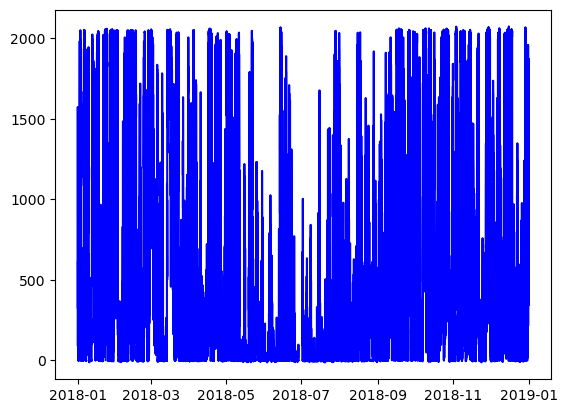

In [5]:
plt.plot(TurbineData['# Date and time'],TurbineData['Power (kW)'],'-b')

Similar plots can be generated directly from the Pandas plotting function:

array([<Axes: xlabel='# Date and time'>, <Axes: xlabel='# Date and time'>],
      dtype=object)

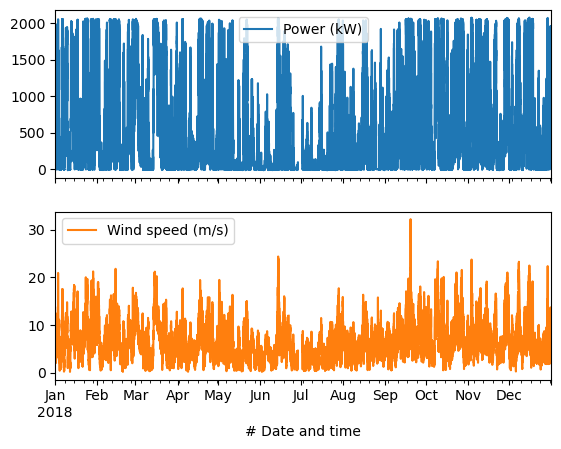

In [6]:
TurbineData.plot(x = '# Date and time', y = ['Power (kW)','Wind speed (m/s)'], subplots = True)

Pair plots are great for getting an overview of dependencies between data (such as correlations). One needs to limit the number of variables to plot, otherwise the plot will get unreadable. 

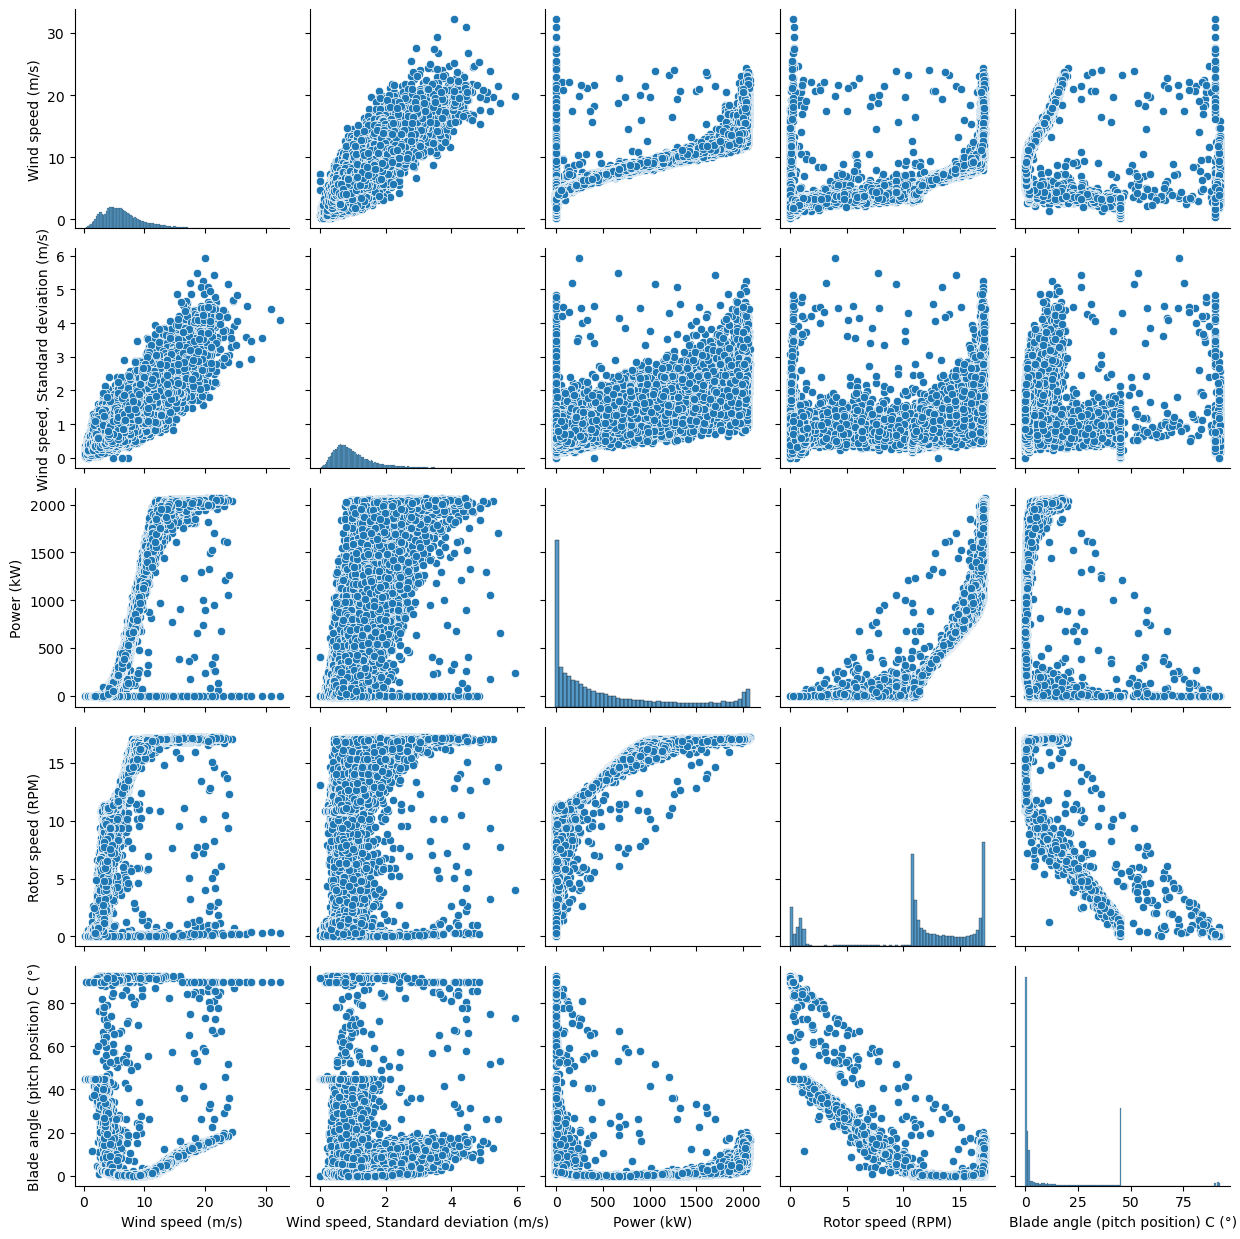

In [7]:
pairplot_vars = ['Wind speed (m/s)', 
                 'Wind speed, Standard deviation (m/s)',
                 'Power (kW)',
                 'Rotor speed (RPM)',
                 'Blade angle (pitch position) C (°)']
sns.pairplot(TurbineData[pairplot_vars])
plt.tight_layout()

# 1.1 Descriptive statistics and sample properties

For simplicity, in this part of the notebook we will take just a single series - the wind speed. 

In [8]:
Wsp = TurbineData['Wind speed (m/s)'].copy()

In [9]:
# Mean, standard deviation, skewness, kurtosis

Wsp_mean = np.mean(Wsp) # Mean using an in-built Python function
Wsp_std = np.std(Wsp, ddof = 1)# Standard deviation using an in-built Python function

Wsp_skew = stats.skew(Wsp.loc[Wsp.isna()==False])
Wsp_kurt = stats.kurtosis(Wsp.loc[Wsp.isna()==False])

print('Mean: ' + str(Wsp_mean))
print('Standard deviation: ' + str(Wsp_std))
print('Skewness: ' + str(Wsp_skew))
print('Excess kurtosis: ' + str(Wsp_kurt))

Mean: 6.60345510954611
Standard deviation: 3.6718264810698287
Skewness: 1.0894583910277273
Excess kurtosis: 1.4245067285786845


Text(0, 0.5, 'Counts')

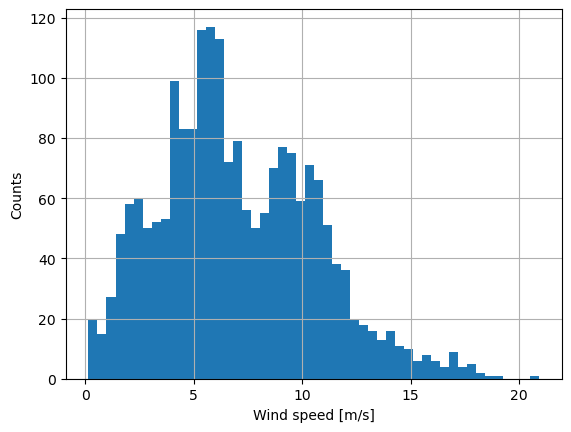

In [10]:
# PLOT A HISTOGRAM OF THE WIND SPEED DATA
Wsp[:2000].hist(bins = 50) # Change the first and second numbers to study the effect of sample size and bin widths respectively
plt.xlabel('Wind speed [m/s]')
plt.ylabel('Counts')

## Computing empirical PDF and CDF

### Computing a cumulative distribution function (CDF) empirically
By calling the PDF and CDF *empirical*, we mean computing these statistical quantities directly from observations (data), without taking assumptions about distribution family or parameters. 
The empirical cumulative distribution function of a data sample can be obtained by ranking the realizations $y_i = f(x_i)$, $i = 1,...,n$ according to their values:

$F_k = \frac{k}{(n + 1)}$

where $y_{k+1} >= y_{k} >= y_{k-1},...$, and the result $F_k$ is the cumulative distribution function value of a point with rank $k$, and $n$ is the total number of data points in a sample. The expression $k/(n+1)$ means that the observed quantities are assumed to be uniformly distributed between 0 and 1, which will asymptotically be the correct behaviour (i.e., useful for large samples). The denominator value $n+1$ is chosen so that the last point in the sequence (when $k = n$) is always less than 1, meaning that there is no artificially imposed upper bound of the distribution at $y_n$. 

In order to plot the sample (empirical) cdf based on the formula defined above, we have to start with sorting the data. This is done with the _np.sort()_ function where the default behaviour is sorting in ascending order. Defining the data point ranks can be done by creating a numpy array of integers using the function _np.arange()_.

Text(0, 0.5, 'Cumulative probability')

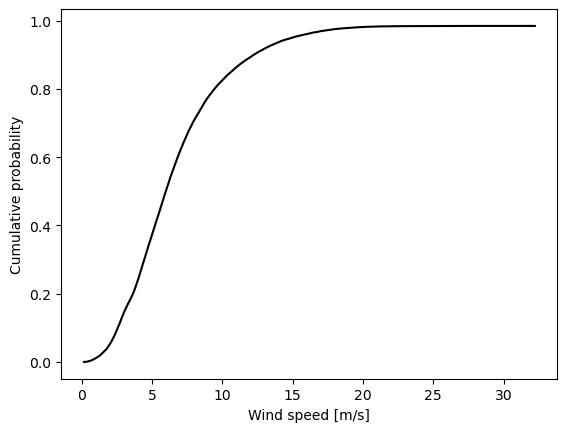

In [11]:
Wsp_sort = np.sort(Wsp) # Ascending order is the default one
Fx = np.arange(1,len(Wsp_sort)+1)/(len(Wsp_sort)+1)

plt.plot(Wsp_sort,Fx,'-k')
plt.xlabel('Wind speed [m/s]')
plt.ylabel('Cumulative probability')

### Computing a probability density function (pdf) empirically

We already plotted a histogram of the data. It looks a lot like a probability density function (pdf), but it does not exactly correspond to a pdf. What is the main difference?

The correct answer is: the y-axis, the scale given by the histogram is just number of counts and depends on the sample size. The pdf is like an asymptotic case of a histogram with an infinitesimal bin width. In order to turn a histogram into a probability density function, we can use a key property of the pdf, which is:

$\int_{-\infty}^{\infty}f(x)dx = 1$

Using the above property, an empirical pdf can be obtained from a data sample with the following steps:

1) Split the data into equally-sized bins, and count the occurrences in each bin (i.e., make a histogram)
2) Compute the definite integral of the histogram counts with respect to the bins, using a numerical integration procedure
3) Normalize the histogram counts by dividing with the integral from point 2)

The empirical pdf from the data is represented by the normalized histogram counts, and is defined at the bin centers. 

As a help: 
- We have defined a simple integration function - "rectangle rule". Note that the rule requires computing distance between bin edges - hence the number of points (edges) in x is one more than the counts (y).
- In order to get the histogram as an array rather than a plot, you can use the *np.histogram* command

In [12]:
# SIMPLE INTEGRATION FUNCTION
def rectangle_rule(x,y):
    res = np.sum(np.diff(x[0:y.shape[0]+1])*y)
    return res

# NUMERICAL PDF COMPUTATION

Wsp_hist = np.histogram(Wsp.loc[Wsp.isna()==False],bins = 30)
Wsp_counts = Wsp_hist[0]
Wsp_bins = Wsp_hist[1]

Wsp_integral = rectangle_rule(Wsp_bins,Wsp_counts)
Wsp_pdf = Wsp_counts/Wsp_integral


IntCheck = rectangle_rule(Wsp_bins,Wsp_pdf)
print('Integral of the pdf: ' + str(IntCheck))

Integral of the pdf: 1.0000000000000002


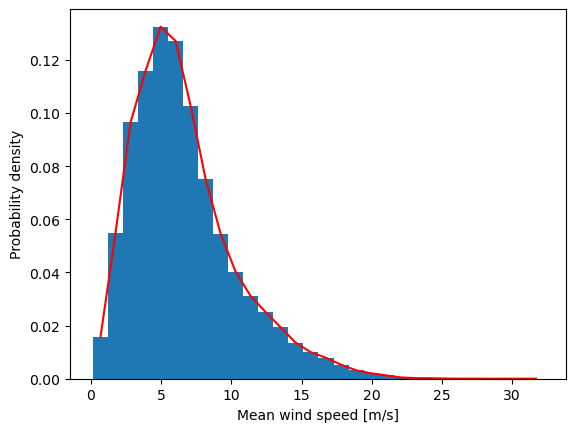

In [13]:
# PLOT NUMERICAL PDF

Wsp_binsc = Wsp_bins[:-1] + np.diff(Wsp_bins)/2 # Find the bin centers for plotting (histogram is based on bin edges!)
plt.bar(Wsp_binsc,Wsp_pdf,width = 1.1)
plt.plot(Wsp_binsc,Wsp_pdf,'-r')
plt.xlabel('Mean wind speed [m/s]')
plt.ylabel('Probability density')
plt.show()

## Effect of sample size

Let us assume we take repeated i.i.d (independent and identically distributed) samples of equal size from a given population. Our goal is to determine the population mean. The sample mean should be an unbiased estimator of the population mean. But the sample mean only converges to the true mean of the population when the sample size tends to infinity. Following the law of large numbers, the variance of the mean of a sample will be inversely proportional to the sample size (with a coefficient of $1/\sqrt{N}$ where $N$ is the sample size.)

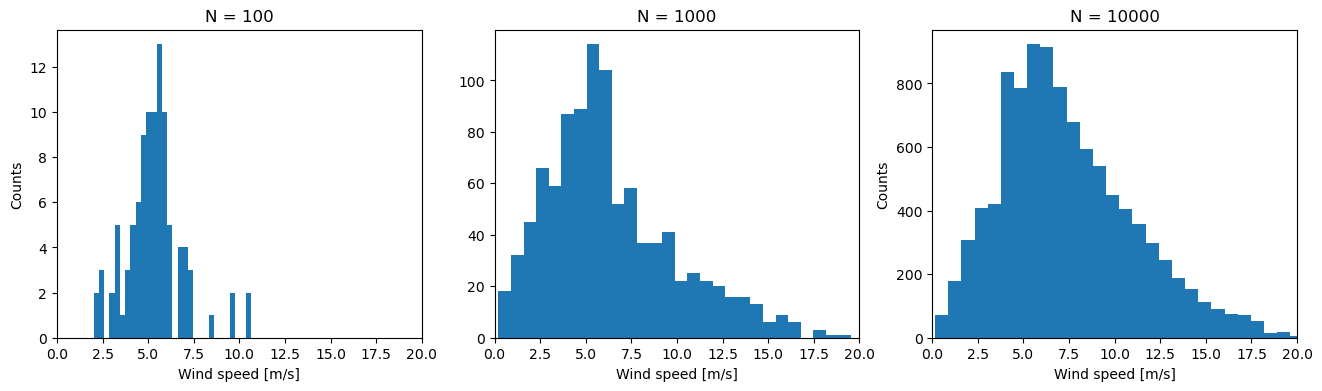

In [14]:
fig2, ax2 = plt.subplots(1,3,figsize = (16,4))
ax2[0].hist(Wsp[:100],30)
ax2[0].set_xlim([0,20])
ax2[0].set_xlabel('Wind speed [m/s]')
ax2[0].set_ylabel('Counts')
ax2[0].set_title('N = 100')
ax2[1].hist(Wsp[:1000],30)
ax2[1].set_xlim([0,20])
ax2[1].set_xlabel('Wind speed [m/s]')
ax2[1].set_title('N = 1000')
ax2[2].set_ylabel('Counts')
ax2[2].hist(Wsp[:10000],30)
ax2[2].set_xlim([0,20])
ax2[2].set_xlabel('Wind speed [m/s]')
ax2[2].set_ylabel('Counts')
ax2[2].set_title('N = 10000')

plt.show()


Ensemble stds = [0.3144322  0.11784489 0.03571619]


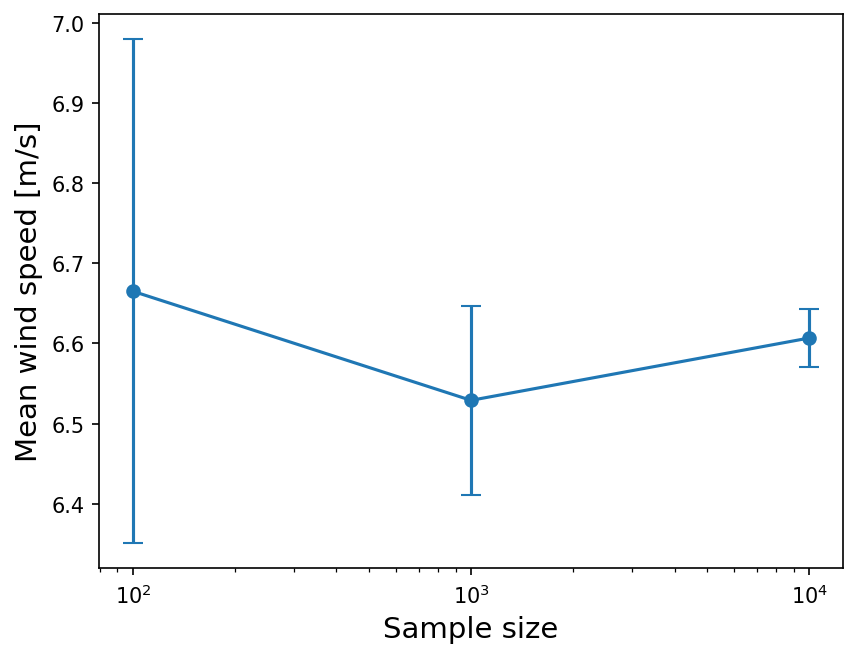

In [15]:
# Test - different sample sizes, we draw samples several times

Nsamples = 10
Sample_sizes = [100,1000,10000]
Ensemble_Means = np.zeros(len(Sample_sizes))
Ensemble_Stds = np.zeros(len(Sample_sizes))

nanWsp = Wsp.loc[Wsp.isna()==False]

for j in range(len(Sample_sizes)):
    Means = np.zeros(Nsamples)

    for i in range(Nsamples):
        Xi = np.random.choice(nanWsp, size = Sample_sizes[j])
        Means[i] = np.mean(Xi)
    
    Ensemble_Means[j] = np.mean(Means)
    Ensemble_Stds[j] = np.std(Means)

fig3,ax3 = plt.subplots(1,1,dpi = 150)
ax3.errorbar(Sample_sizes,Ensemble_Means, Ensemble_Stds, marker = 'o', capsize = 5)
ax3.set_xlabel('Sample size', fontsize = 14)
ax3.set_ylabel('Mean wind speed [m/s]',fontsize = 14)
ax3.set_xscale('log')
print('Ensemble stds = ' + str(Ensemble_Stds))

# 1.2. Data cleaning (filtering irrelevant or missing data)

Key element to filter on is the *operating status* of the turbine. Often the status may be available as a variable in SCADA. If unavailable, there are several techniques to determine the status:
- Heuristics (if-then-else rules, logic - based on know turbine behavior patterns)
- Clustering (unsupervised approach, "discovering" rules rather than specifying them)
- Variance-based outlier filtering

Text(0, 0.5, 'Power [kW]')

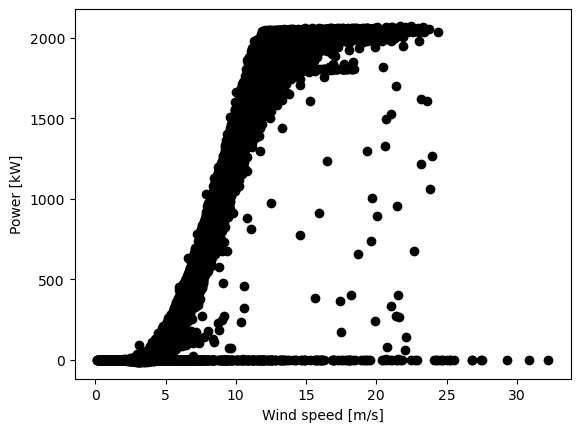

In [16]:
plt.plot(TurbineData['Wind speed (m/s)'],TurbineData['Power (kW)'],'ok')
plt.xlabel('Wind speed [m/s]')
plt.ylabel('Power [kW]')

## Filtering by heuristics (rules)

Let us first try to filter the data by applying rules. Variables that are often useful: rpm, power and pitch of the wind turbine.

In [17]:
filter_variables = ['Power, Minimum (kW)', 
                    'Power, Maximum (kW)', 
                    'Power (kW)',
                    'Rotor speed, Min (RPM)',
                    'Rotor speed, Max (RPM)',
                    'Rotor speed (RPM)',
                    'Blade angle (pitch position) C, Min (°)',
                    'Blade angle (pitch position) C, Max (°)',
                    'Blade angle (pitch position) C (°)'
                    ]

In [18]:
TurbineData[filter_variables]

,"Power, Minimum (kW)","Power, Maximum (kW)",Power (kW),"Rotor speed, Min (RPM)","Rotor speed, Max (RPM)",Rotor speed (RPM),"Blade angle (pitch position) C, Min (°)","Blade angle (pitch position) C, Max (°)",Blade angle (pitch position) C (°)
0,77.739998,833.130005,327.059998,11.110000,15.940000,12.250000,NaN,NaN,NaN
1,610.950012,2107.610107,1512.010010,14.960000,17.610001,16.830000,NaN,NaN,NaN
2,881.270020,2085.689941,1573.430054,16.670000,17.500000,17.080000,NaN,NaN,NaN
3,754.909973,2086.620117,1290.880005,16.020000,17.430000,16.950001,NaN,NaN,NaN
4,700.799988,1880.800049,1249.369995,15.590000,17.379999,16.900000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
52555,386.555054,2072.072998,1129.254150,12.907824,17.296524,16.040224,NaN,NaN,0.992498
52556,430.817291,2054.381104,1042.812500,13.496983,17.225964,16.170698,NaN,NaN,0.404215
52557,244.816803,1847.530029,794.825378,11.577403,17.198124,15.370248,NaN,NaN,0.111323
52558,345.611664,2074.079102,1033.603271,12.692052,17.420963,16.007500,NaN,NaN,0.505522


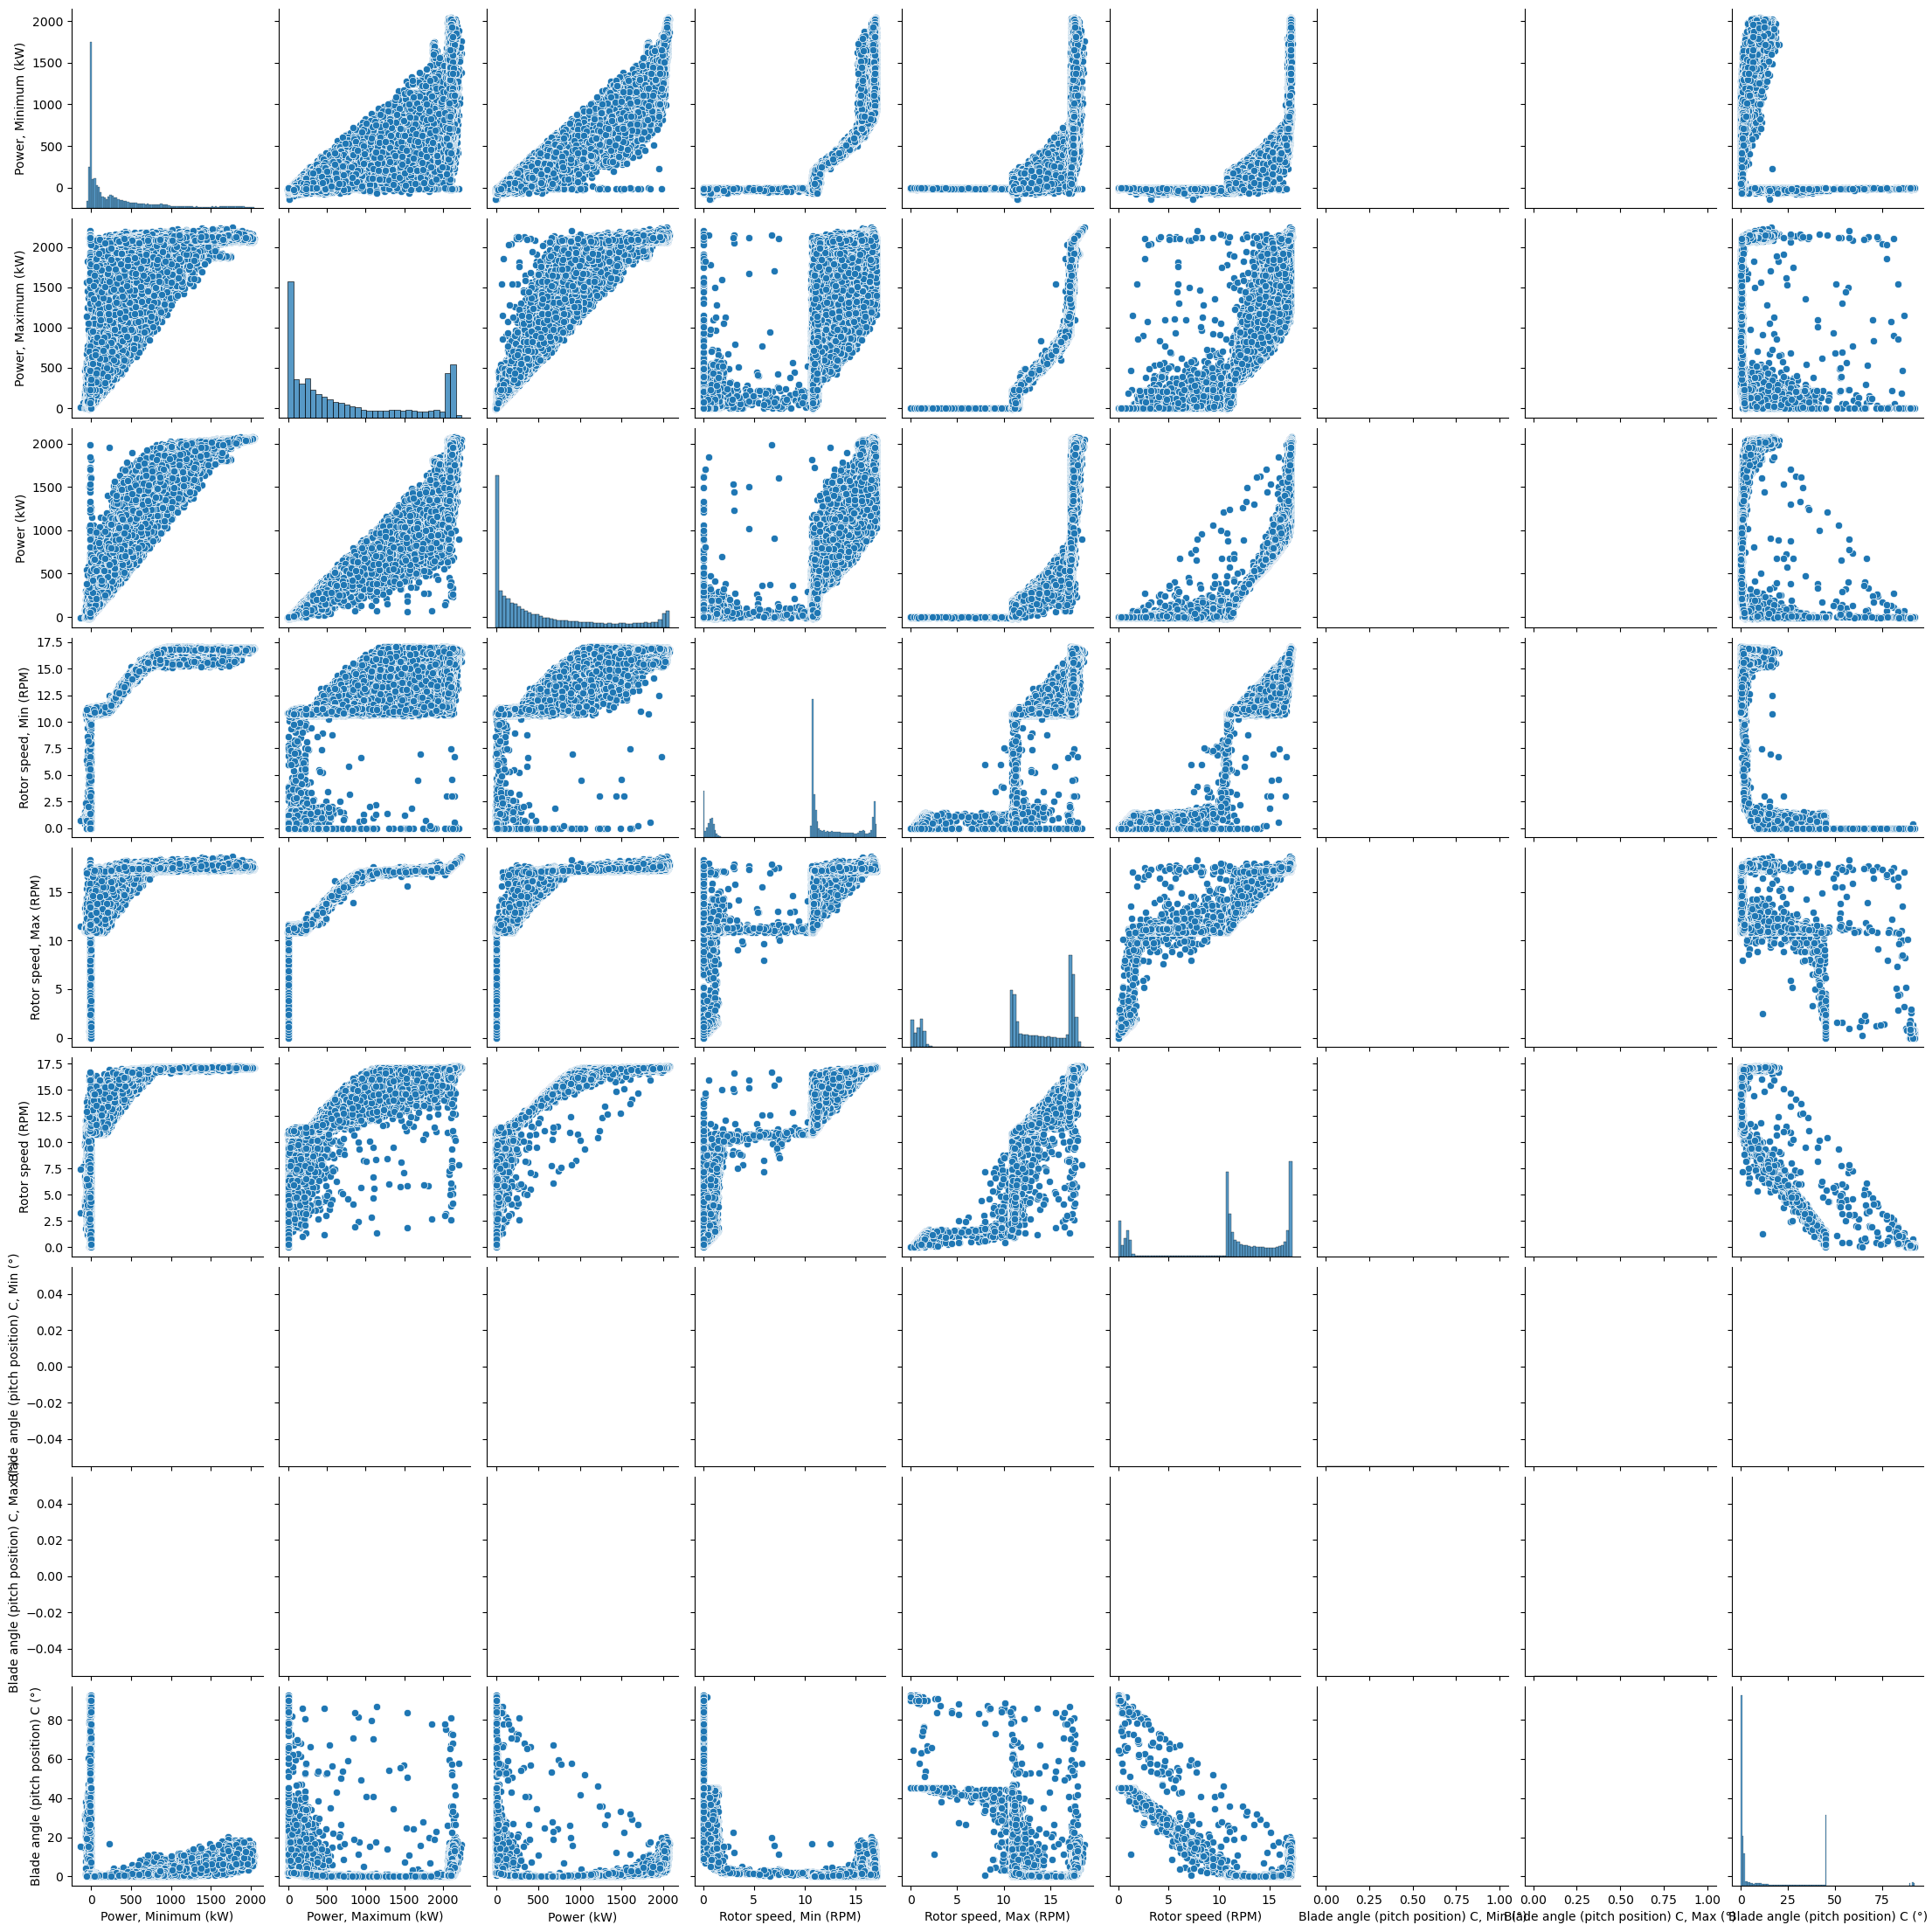

In [19]:
sns.pairplot(TurbineData[filter_variables])

Along with the mean values, the extremes (min or max) will be often useful criteria as certain minima/maxima may occur at the edges of a domain of interest (e.g., minimum rotor/generator rpm is required for power production)

Text(0, 0.5, 'Minimum rotor speed [rpm]')

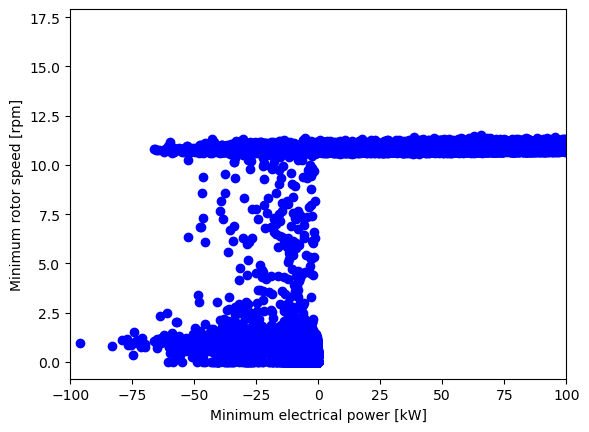

In [20]:
plt.plot(TurbineData['Power, Minimum (kW)'],TurbineData['Rotor speed, Min (RPM)'],'ob')
plt.gca().set_xlim([-100,100])
plt.xlabel('Minimum electrical power [kW]')
plt.ylabel('Minimum rotor speed [rpm]')

Unfortunately, looks like the pitch angle data is not very reliable. We only seem to have pitch data for one blade (typically OK given that the turbines mostly work with collective pitching), and even data for blade C is full of gaps:

In [21]:
TurbineData['Blade angle (pitch position) C (°)'].isna().sum()

np.int64(18050)

In order to define the turbine status, we will use "binary masks". These will specify whether the turbine is in a certain operational state or not. Given that there are multiple operational states, we need to take care that these masks are mutually exclusive (only one state should be active at a time). Finally, for easier operations on the full dataset, we would add a new column in the dataframe, specifying the operating status of the turbine. 

The following cell makes an index selecting data with continuous power production

In [22]:
ProductionOK = TurbineData['Rotor speed, Min (RPM)'] > 10

Text(0, 0.5, 'Electrical power [kW]')

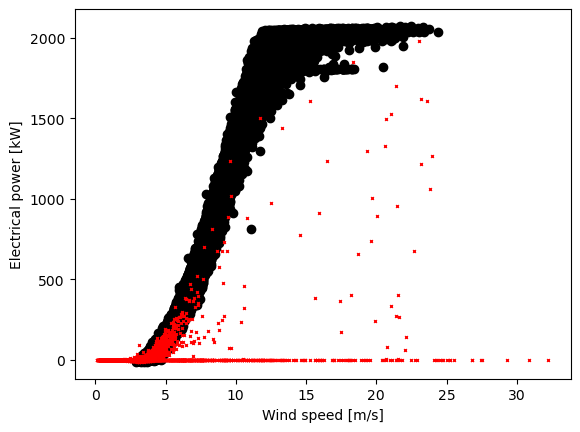

In [23]:
plt.plot(TurbineData.loc[ProductionOK==True,'Wind speed (m/s)'],TurbineData.loc[ProductionOK == True,'Power (kW)'],'ok')
plt.plot(TurbineData.loc[ProductionOK==False,'Wind speed (m/s)'],TurbineData.loc[ProductionOK == False,'Power (kW)'],'xr', markersize = 2)
plt.xlabel('Wind speed [m/s]')
plt.ylabel('Electrical power [kW]')

Text(0, 0.5, 'Maximum rotor speed [rpm]')

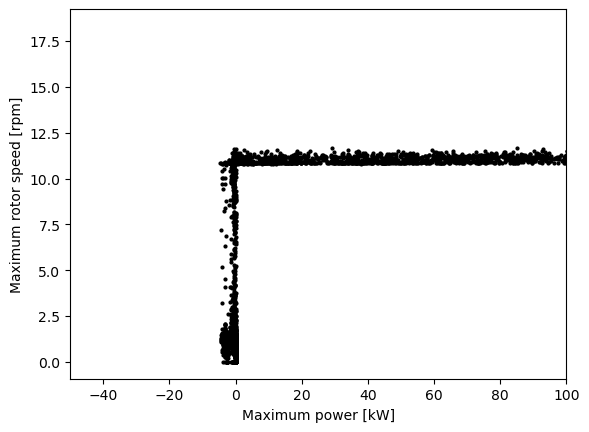

In [24]:
plt.plot(TurbineData.loc[ProductionOK==False,'Power, Maximum (kW)'],TurbineData.loc[ProductionOK==False,'Rotor speed, Max (RPM)'],'ok', markersize = 2)
plt.gca().set_xlim([-50,100])
plt.xlabel('Maximum power [kW]')
plt.ylabel('Maximum rotor speed [rpm]')

In [25]:
TurbineData.loc[TurbineData['Rotor speed, Max (RPM)']<10,'Power, Maximum (kW)'].max()

0.064020000398159

In addition to continuous power production, we distinguish three additional states:
- Idling: the turbine is not producing energy, waiting for the wind to pick up above cut-in wind speed - while the rotor is let rotate slowly to avoid potential component (lubrication) damage.
- Parked: the turbine is not producing power and the rotor is stationary
- Transient: a period with at least partial power production operation, but evidence that the turbine has changed operating status.

In [26]:
Idling_index = (ProductionOK == False) & (TurbineData['Power, Maximum (kW)'] < 0.065) & (TurbineData['Rotor speed, Max (RPM)'] > 0)
Transient_index = (ProductionOK == False) & (TurbineData['Power, Maximum (kW)'] > 0.065)
Parked_index = (ProductionOK == False) & (Transient_index==False) & (Idling_index == False)

The potential curtailment event (anomaly in the power curve) is still not filtered out. If we are lucky, there may be a channel in the data that flags the periods with curtailment:


array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

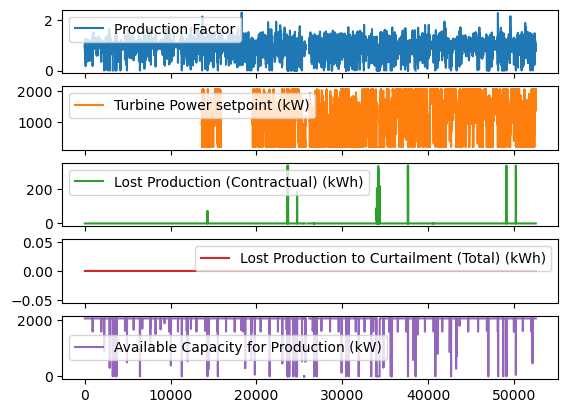

In [27]:
TurbineData[['Production Factor','Turbine Power setpoint (kW)','Lost Production (Contractual) (kWh)','Lost Production to Curtailment (Total) (kWh)','Available Capacity for Production (kW)']].plot(subplots = True)

It seems however that the specific curtailment event is not captured by the available flags. A closer inspection of the data reveals the anomalous points have mean power in the range of 1800-1810kW and the wind speed is > 14m/s. We flag these points with another binary mask. 

In [28]:
WeirdIndex = (TurbineData['Wind speed (m/s)'] > 14) & (TurbineData['Power (kW)'] > 1800) & (TurbineData['Power (kW)'] < 1810)

In [29]:
NormalProd_index = (ProductionOK == True) & (WeirdIndex == False)

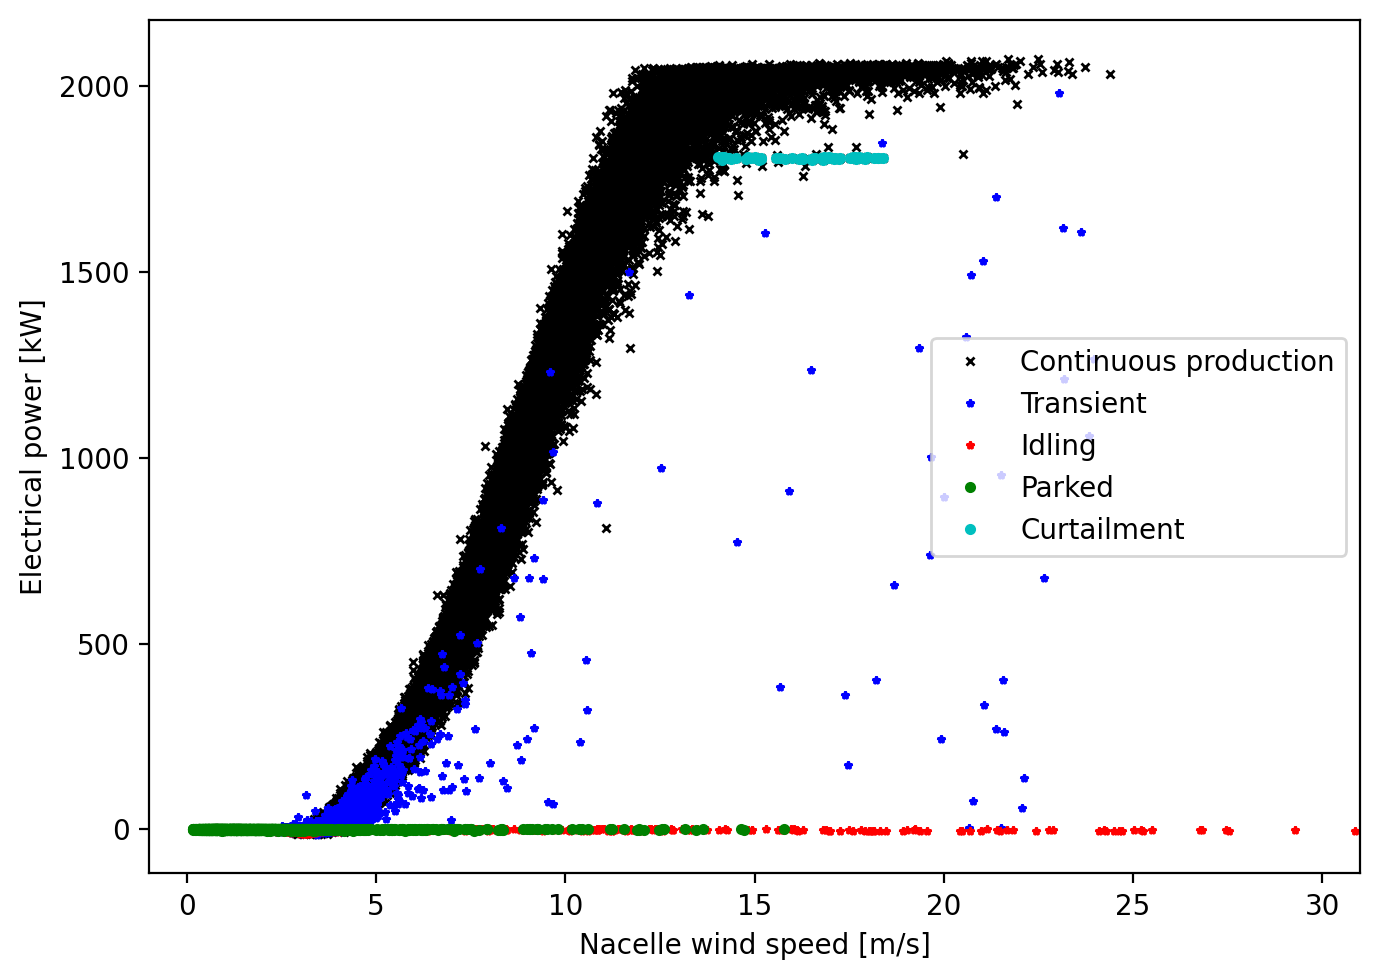

In [30]:
figure1,ax1 = plt.subplots(1,1,figsize = (7,5), dpi = 200)
ax1.plot(TurbineData.loc[ProductionOK,'Wind speed (m/s)'],TurbineData.loc[ProductionOK,'Power (kW)'],'xk',markersize = 3, label = 'Continuous production')
ax1.plot(TurbineData.loc[Transient_index,'Wind speed (m/s)'],TurbineData.loc[Transient_index,'Power (kW)'],'*b',markersize = 3, label = 'Transient')
ax1.plot(TurbineData.loc[Idling_index,'Wind speed (m/s)'],TurbineData.loc[Idling_index,'Power (kW)'],'*r',markersize = 3, label = 'Idling')
ax1.plot(TurbineData.loc[Parked_index,'Wind speed (m/s)'],TurbineData.loc[Parked_index,'Power (kW)'],'og',markersize = 3, label = 'Parked')
ax1.plot(TurbineData.loc[WeirdIndex,'Wind speed (m/s)'],TurbineData.loc[WeirdIndex,'Power (kW)'],'oc',markersize = 3, label = 'Curtailment')
ax1.set_xlabel('Nacelle wind speed [m/s]')
ax1.set_ylabel('Electrical power [kW]')
ax1.set_xlim([-1,31])
#ax1.set_ylim([1800, 1810])
ax1.legend()
plt.tight_layout()
plt.show()


Finally, we have assigned status flags to all data points. It is useful to have the status flag as an additional column in the dataframe, so that we can filter for different status at any time. 

In [31]:
TurbineData["Status"] = None

In [32]:
TurbineData.loc[NormalProd_index,"Status"] = "Production"
TurbineData.loc[(ProductionOK & WeirdIndex),"Status"] = "Curtailed"
TurbineData.loc[Idling_index,"Status"] = "Idling"
TurbineData.loc[Transient_index,"Status"] = "Transient"
TurbineData.loc[Parked_index,"Status"] = "Parked"

In [33]:
TurbineData["Status"]

0        Production
1        Production
2        Production
3        Production
4        Production
            ...    
52555    Production
52556    Production
52557    Production
52558    Production
52559    Production
Name: Status, Length: 52560, dtype: object

## Filtering by data clustering

It is possible to let an algorithm identify the operating status of the turbine, by grouping data into clusters. The success of the analysis is not always guaranteed given the unsupervised nature of the clustering algorithm, meaning the algorithm does not receive any information about how the different classes of operating status relate and distinguish between each other.

In [34]:
ClusteringInput = TurbineData.loc[:,['Wind speed (m/s)',
                                     'Wind speed, Standard deviation (m/s)',
                                     'Wind speed, Minimum (m/s)', 
                                     'Wind speed, Maximum (m/s)',
                                     'Power (kW)',
                                     'Power, Standard deviation (kW)', 
                                     'Power, Minimum (kW)',
                                     'Power, Maximum (kW)',
                                     'Rotor speed (RPM)',
                                     'Rotor speed, Min (RPM)',
                                     'Rotor speed, Max (RPM)',
                                     'Rotor speed, Standard deviation (RPM)']]
                                    #'Blade angle (pitch position) C (°)']]


NanIndexClustering = ClusteringInput.isna().sum(axis=1) == 0



In [35]:
# Model that automatically selects number of clusters (SLOW!!!)
#MeanShift_model = sklearn.cluster.MeanShift().fit(ClusteringInput.loc[NanIndexClustering,:])


In [36]:
Kmeans_model = sklearn.cluster.KMeans(n_clusters = 6).fit(ClusteringInput.loc[NanIndexClustering,:])

In [37]:
Kmeans_clusters_0 = Kmeans_model.predict(ClusteringInput[NanIndexClustering==True])
TurbineData["Kmeans_clusters"] = None
TurbineData.loc[NanIndexClustering==True, "Kmeans_clusters"] = Kmeans_clusters_0

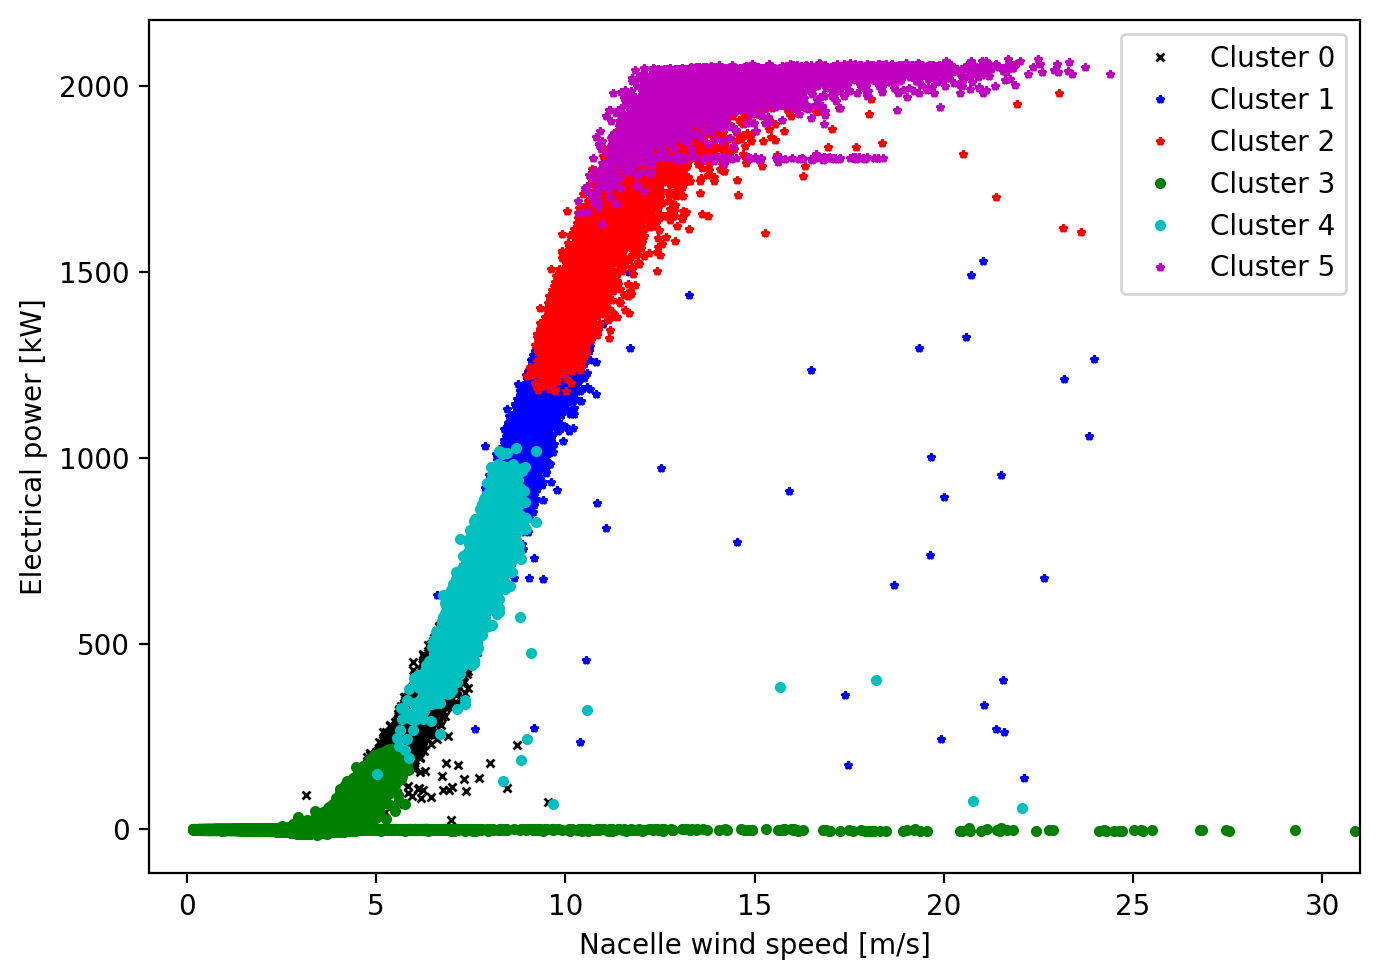

In [38]:
figure11,ax11 = plt.subplots(1,1,figsize = (7,5), dpi = 200)
ax11.plot(TurbineData.loc[TurbineData["Kmeans_clusters"]==0,'Wind speed (m/s)'],TurbineData.loc[TurbineData["Kmeans_clusters"]==0,'Power (kW)'],'xk',markersize = 3, label = 'Cluster 0')
ax11.plot(TurbineData.loc[TurbineData["Kmeans_clusters"]==1,'Wind speed (m/s)'],TurbineData.loc[TurbineData["Kmeans_clusters"]==1,'Power (kW)'],'*b',markersize = 3, label = 'Cluster 1')
ax11.plot(TurbineData.loc[TurbineData["Kmeans_clusters"]==2,'Wind speed (m/s)'],TurbineData.loc[TurbineData["Kmeans_clusters"]==2,'Power (kW)'],'*r',markersize = 3, label = 'Cluster 2')
ax11.plot(TurbineData.loc[TurbineData["Kmeans_clusters"]==3,'Wind speed (m/s)'],TurbineData.loc[TurbineData["Kmeans_clusters"]==3,'Power (kW)'],'og',markersize = 3, label = 'Cluster 3')
ax11.plot(TurbineData.loc[TurbineData["Kmeans_clusters"]==4,'Wind speed (m/s)'],TurbineData.loc[TurbineData["Kmeans_clusters"]==4,'Power (kW)'],'oc',markersize = 3, label = 'Cluster 4')
ax11.plot(TurbineData.loc[TurbineData["Kmeans_clusters"]==5,'Wind speed (m/s)'],TurbineData.loc[TurbineData["Kmeans_clusters"]==5,'Power (kW)'],'*m',markersize = 3, label = 'Cluster 5')
ax11.set_xlabel('Nacelle wind speed [m/s]')
ax11.set_ylabel('Electrical power [kW]')
ax11.set_xlim([-1,31])
#ax1.set_ylim([1800, 1810])
ax11.legend()
plt.tight_layout()
plt.show()

# PART 2: FEATURE SELECTION AND MODEL INPUT PREPARATION

Computing the power requires just a few features. Thus it is an easy variable to start with. 

In [39]:
PowerFeatures = ['Power (kW)','Wind speed (m/s)',
       'Wind speed, Standard deviation (m/s)',
       'Wind speed, Minimum (m/s)', 'Wind speed, Maximum (m/s)',
       'Long Term Wind (m/s)', 'Wind speed Sensor 1 (m/s)',
       'Wind speed Sensor 1, Standard deviation (m/s)',
       'Wind speed Sensor 1, Minimum (m/s)',
       'Wind speed Sensor 1, Maximum (m/s)', 'Wind speed Sensor 2 (m/s)',
       'Wind speed Sensor 2, Standard deviation (m/s)',
       'Wind speed Sensor 2, Minimum (m/s)',
       'Wind speed Sensor 2, Maximum (m/s)',
       'Density adjusted wind speed (m/s)', 'Wind direction (°)',
       'Nacelle position (°)', 'Wind direction, Standard deviation (°)',
       'Wind direction, Minimum (°)', 'Wind direction, Maximum (°)',
       'Nacelle position, Standard deviation (°)',
       'Nacelle position, Minimum (°)', 'Nacelle position, Maximum (°)',
       'Vane position 1+2 (°)', 'Vane position 1+2, Max (°)',
       'Vane position 1+2, Min (°)', 'Vane position 1+2, StdDev (°)']

# 2.1 Correlations and general filter-based selection

<Axes: >

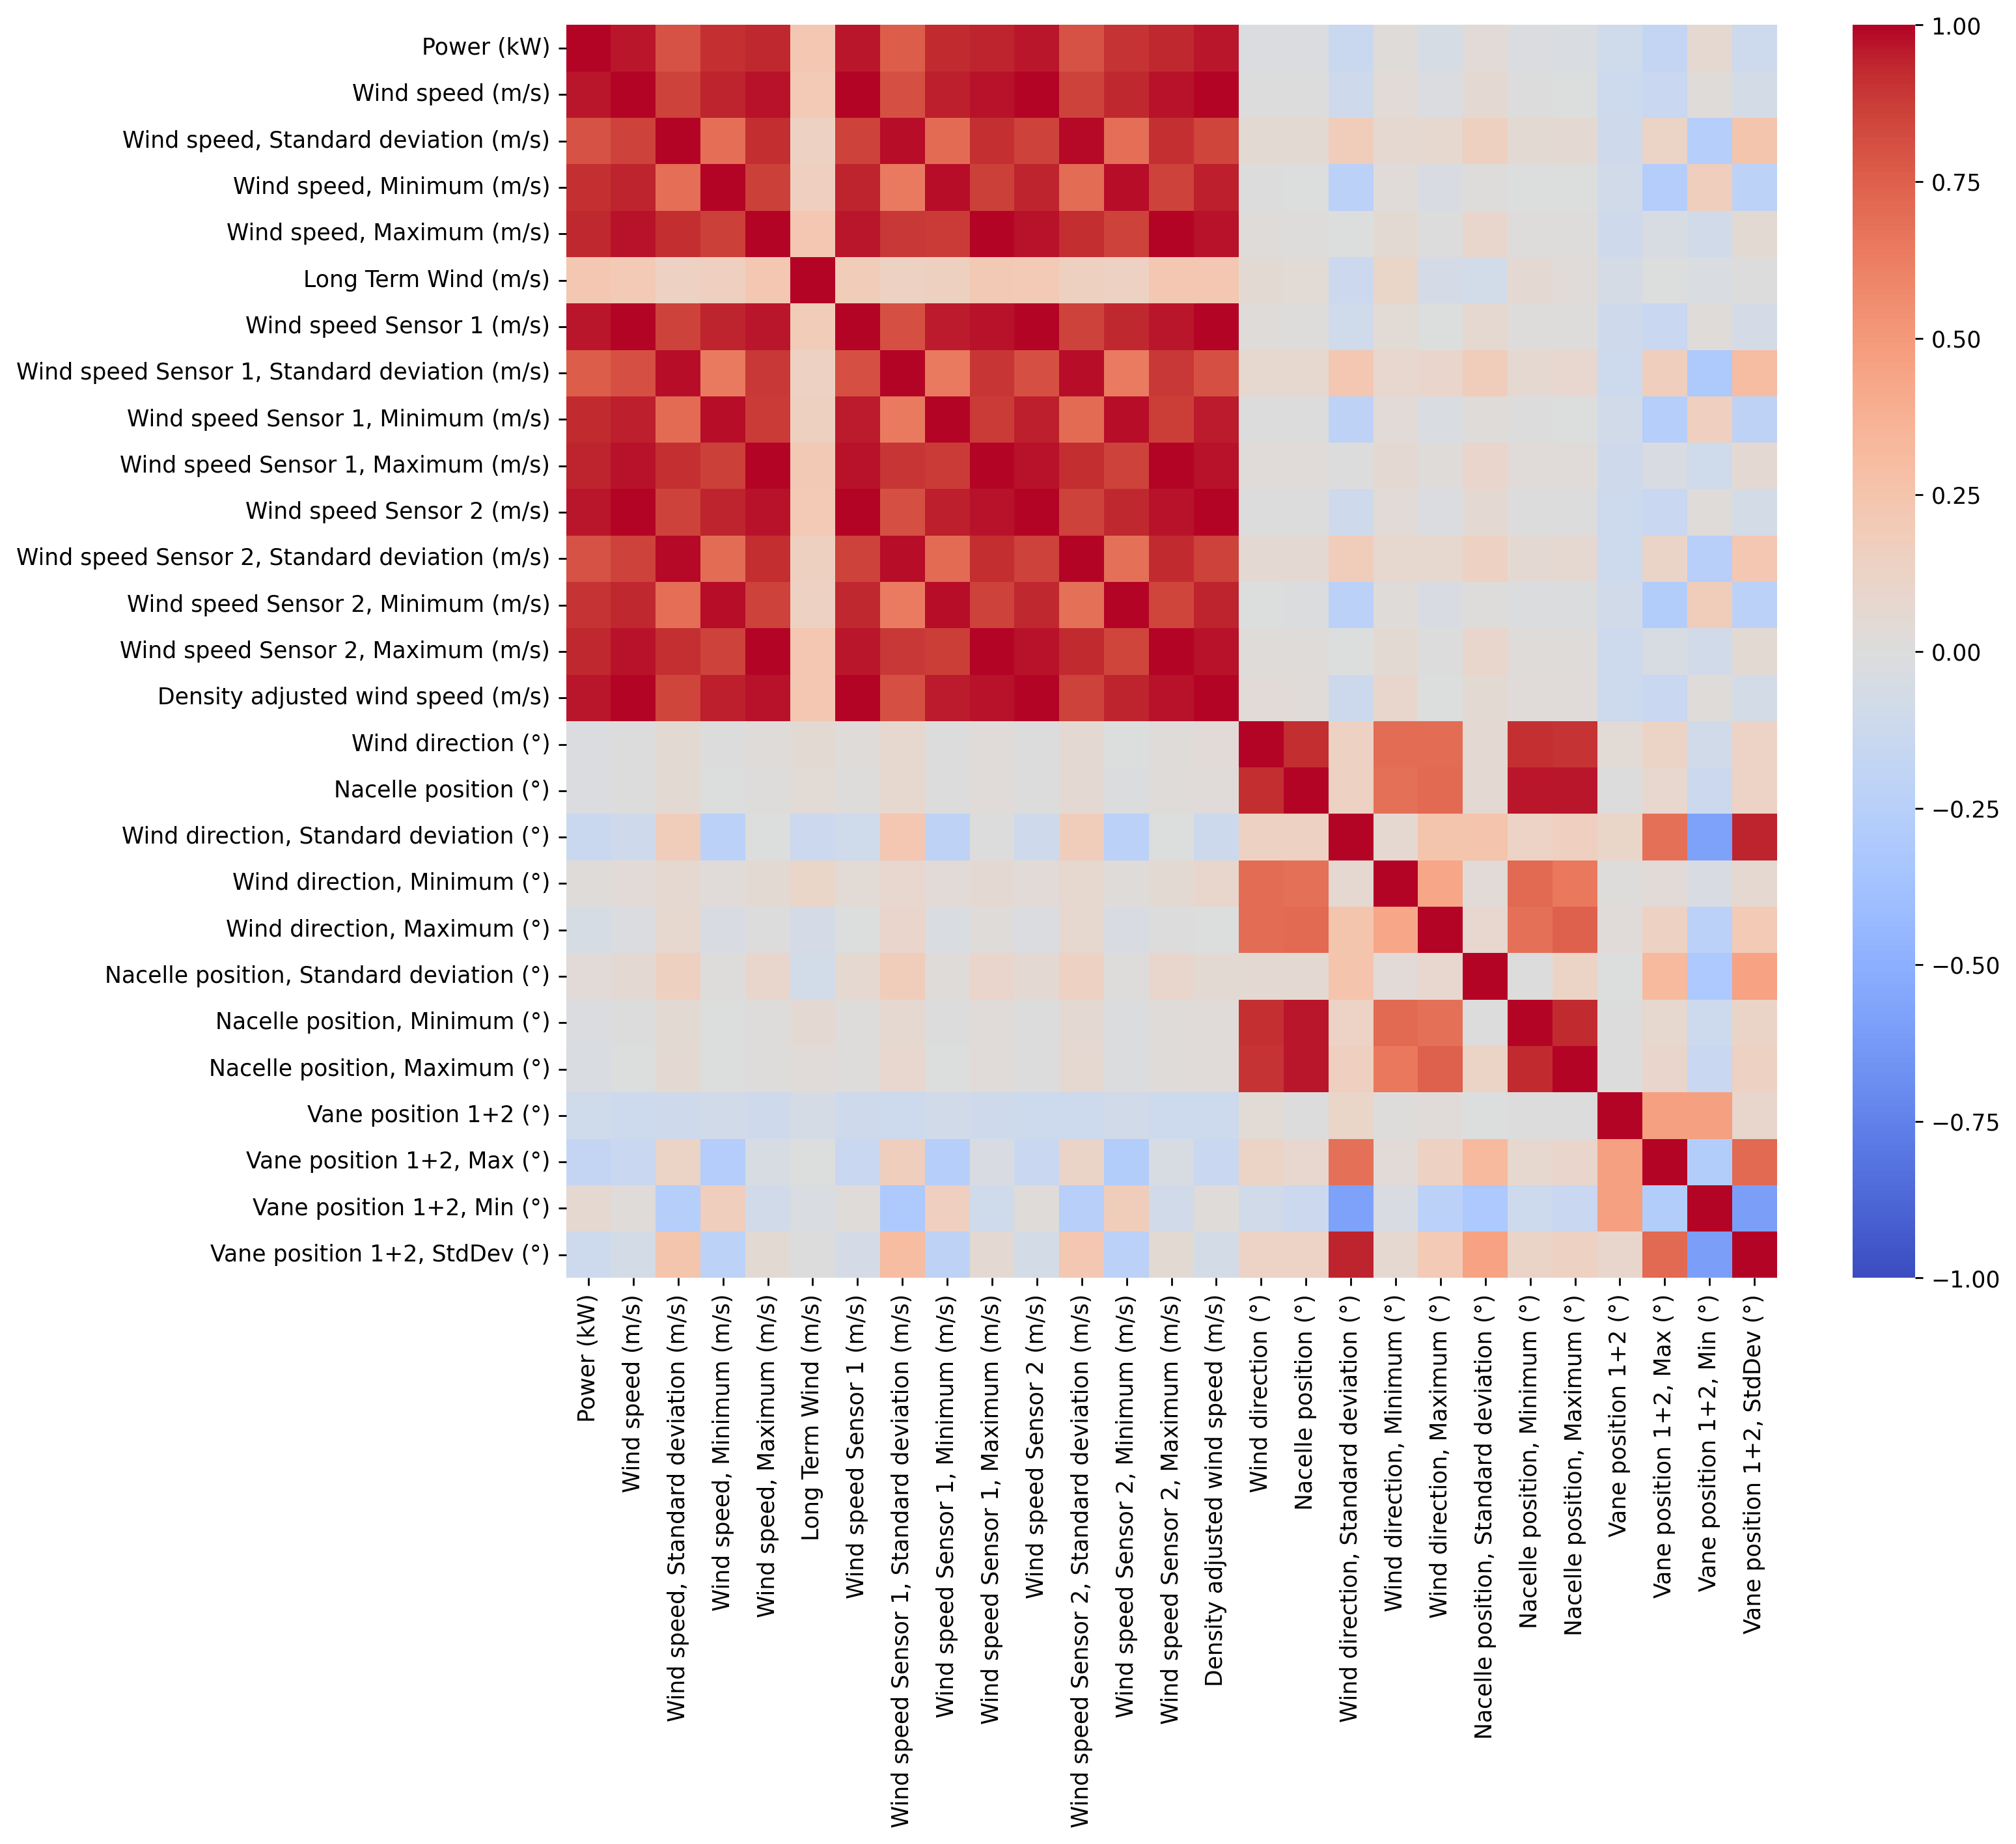

In [40]:
Corr0 = TurbineData.loc[NormalProd_index,PowerFeatures].corr()
#Corr0.style.background_gradient(cmap='coolwarm').format(precision = 2)
fig1 = plt.figure(figsize = (12,10), dpi = 250)
sns.heatmap(Corr0, cmap = 'coolwarm', vmin = -1, vmax = 1)

# 2.2. Univariate feature selection algorithms

With this approach, the effect of each variable on the overall model performance is evaluated independently - either by fitting one-input, one-output models sequentially, or by doing sequential feature elimination (i.e., removing features one by one).

Sklearn provides a range of feature selection methods. An overview:

https://scikit-learn.org/stable/modules/feature_selection.html

List of feature selection libraries:

https://scikit-learn.org/stable/api/sklearn.feature_selection.html


A common property of these feature selection algorithms is that they fit simplified models to the data. In order to apply them appropriately, we need to prepare the model data for training. This is done in the following code cells.

In [41]:
# SELECTING INPUT AND TARGET FEATURE LIST

TargetFeatures = 'Power (kW)'
InputFeatures = ['Wind speed (m/s)',
       'Wind speed, Standard deviation (m/s)',
       'Wind speed, Minimum (m/s)', 'Wind speed, Maximum (m/s)',
       'Density adjusted wind speed (m/s)', 'Wind direction (°)',
       'Wind direction, Standard deviation (°)']

## Model data preparation (train/test set)

In order to run model training, we need feature input- and output- pair observations with all features containing valid data. If we are luckly, most observation rows will contain valid data and we can just use those, while eliminating any row with invalid entries. However, if the data gaps are many, one may consider a data filling technique (for example the pandas forward-fill and back-fill methods). The gap filling approach becomes an essential factor when time dependence in the data points needs to be preserved (for example if working with time series models). 

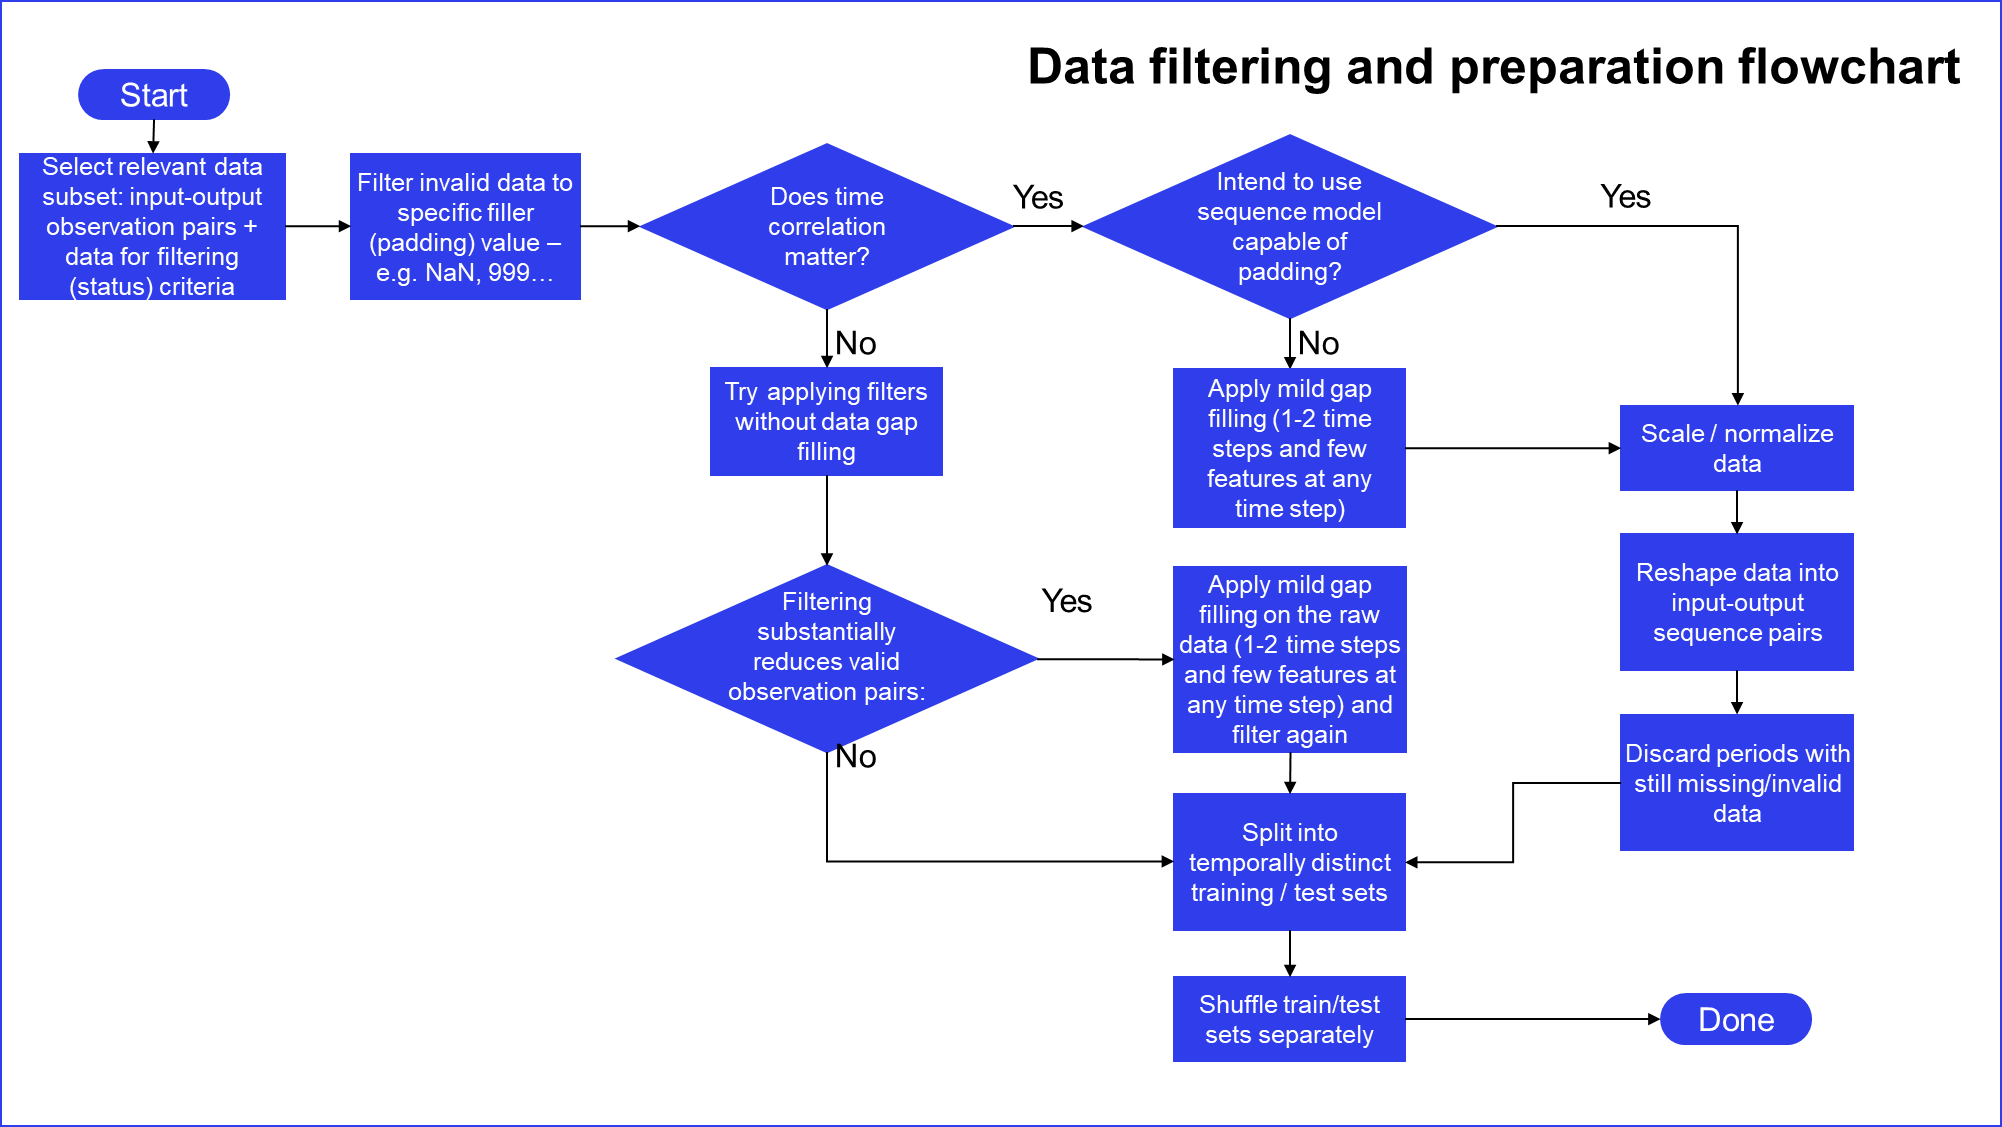

In [42]:
# Identify data rows (input-output pairs) with fully valid data (no NaNs)
NaNindex = (TurbineData[InputFeatures].isna().sum(axis = 1) == 0) & (TurbineData[TargetFeatures].isna() == False)
NaNindex.sum()

np.int64(43002)

Data scaling is a common technique when preparing model inputs. It is useful for two reasons: 
1) Some models like Neural Networks will not fit properly unless the data are standardized
2) Having all model variables standardized makes way for more elaborate interpretations of the model properties, such as sensitivity analysis and statistical tests

In [43]:

Xscaler = sklearn.preprocessing.StandardScaler()
Xscaler.fit(TurbineData[InputFeatures])
Yscaler = sklearn.preprocessing.StandardScaler()
Yscaler.fit(TurbineData[[TargetFeatures]])


,copy,True
,with_mean,True
,with_std,True


## Feature selection by Mutual Information Scores

In [44]:
MutualInformationScores = sklearn.feature_selection.mutual_info_regression(Xscaler.transform(TurbineData.loc[(NaNindex & NormalProd_index),InputFeatures]), Yscaler.transform(TurbineData.loc[(NaNindex & NormalProd_index),[TargetFeatures]]))

c:\Users\nkdi\AppData\Local\anaconda3\envs\Env_2025_edu\Lib\site-packages\sklearn\utils\validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


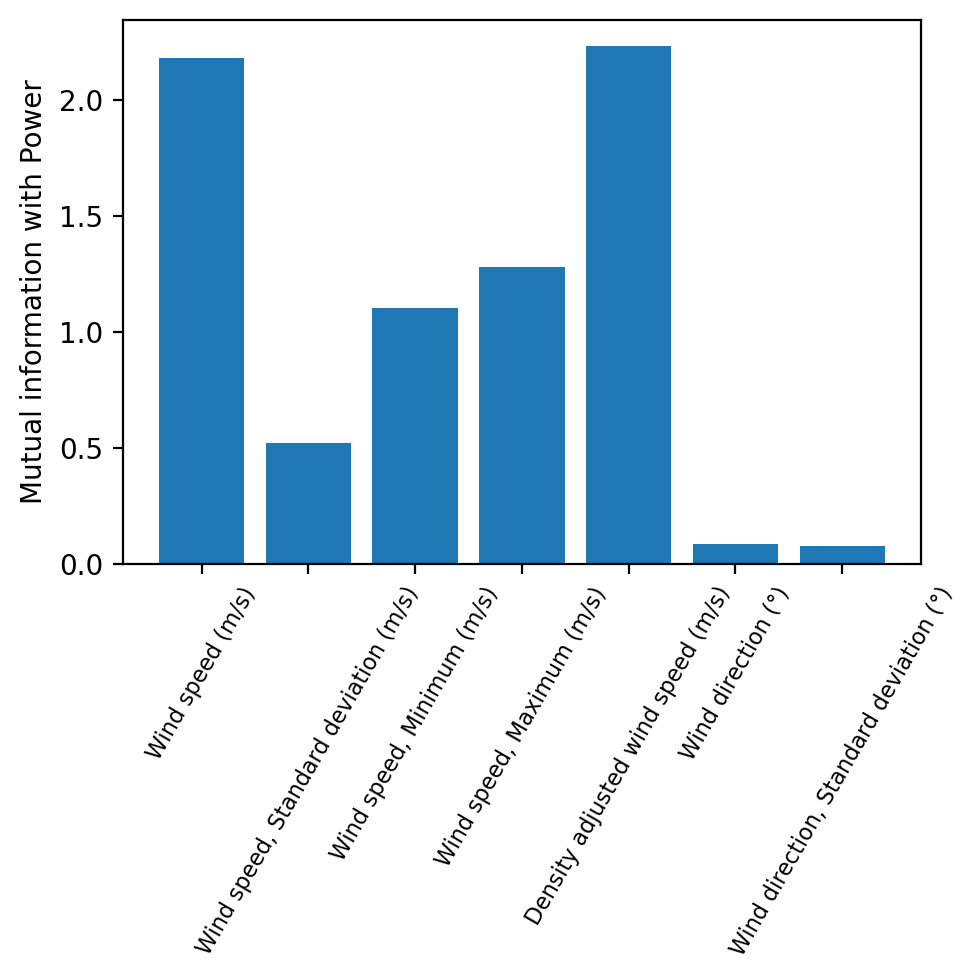

In [45]:
fig2 = plt.figure(figsize = (5,5), dpi = 200)
plt.bar(x = InputFeatures, height=MutualInformationScores)
plt.xticks(rotation = 60, fontsize = 8)
plt.ylabel('Mutual information with Power')
plt.tight_layout()
plt.show()

## Feature selection by recursive feature elimination

This modelling approach is a wrapper method which applies a series of model fits and evaluations. In order to apply it, we need to prepare the data for model training. We will therefore move to the next step (model fitting) and show the wrapper methods after we've prepared the model data

# PART 3: NORMALITY MODEL FITTING

# 3.1 Data selection (normal behavior)

We start by selecting what is a "normal behavior" period. We have already filtered for the periods of normal production. We also know that there is a period with curtailment that could affect our analysis. Let us then identify the time when curtailment occurs (it may be a few events only) and pick normality periods outside the curtailment period.

In [46]:
TurbineData.loc[WeirdIndex,'# Date and time']

1955    2018-01-14 13:50:00
1958    2018-01-14 14:20:00
1962    2018-01-14 15:00:00
1963    2018-01-14 15:10:00
1964    2018-01-14 15:20:00
1965    2018-01-14 15:30:00
1967    2018-01-14 15:50:00
1968    2018-01-14 16:00:00
1969    2018-01-14 16:10:00
1970    2018-01-14 16:20:00
1971    2018-01-14 16:30:00
1972    2018-01-14 16:40:00
1973    2018-01-14 16:50:00
1974    2018-01-14 17:00:00
1975    2018-01-14 17:10:00
1980    2018-01-14 18:00:00
1981    2018-01-14 18:10:00
1982    2018-01-14 18:20:00
1983    2018-01-14 18:30:00
1984    2018-01-14 18:40:00
1985    2018-01-14 18:50:00
1986    2018-01-14 19:00:00
1987    2018-01-14 19:10:00
1988    2018-01-14 19:20:00
1989    2018-01-14 19:30:00
1990    2018-01-14 19:40:00
1991    2018-01-14 19:50:00
1992    2018-01-14 20:00:00
1993    2018-01-14 20:10:00
1994    2018-01-14 20:20:00
1995    2018-01-14 20:30:00
1996    2018-01-14 20:40:00
1997    2018-01-14 20:50:00
1998    2018-01-14 21:00:00
1999    2018-01-14 21:10:00
2000    2018-01-14 2

The overview shows that most curtailments happen over a period in mid-january. We can exlude January from our analysis. 

In [47]:
TrainingPeriodStart = '2018-01-16 00:00:00'
TrainingPeriodEnd = '2018-09-01 00:00:00'
TestPeriodStart = '2018-09-01 00:00:00'
TestPeriodEnd = '2019-01-01 00:00:00'

TrainingPeriod = (TurbineData['# Date and time'] >= TrainingPeriodStart) & (TurbineData['# Date and time'] < TrainingPeriodEnd)
TestingPeriod = (TurbineData['# Date and time'] >= TestPeriodStart) & (TurbineData['# Date and time'] < TestPeriodEnd)

In [48]:
print(np.sum(TrainingPeriod))
print(np.sum(TestingPeriod))

32832
17568


Scaling the data using the previously trained functions (notice - we train the functions only once, and use the same functions throughout the text, to keep consistency)

In [49]:
Xtrain = Xscaler.transform(TurbineData.loc[(TrainingPeriod & NaNindex & NormalProd_index),InputFeatures])
Xtest = Xscaler.transform(TurbineData.loc[(TestingPeriod & NaNindex & NormalProd_index),InputFeatures])

Ytrain = Yscaler.transform(TurbineData.loc[(TrainingPeriod & NaNindex & NormalProd_index),[TargetFeatures]]) # Extra brackets on Target Features needed because it is a 1-D array
Ytest = Yscaler.transform(TurbineData.loc[(TestingPeriod & NaNindex & NormalProd_index),[TargetFeatures]])

# 3.2 Model choice and fitting

To begin with, we will fit two widely popular model choices:
- Feedforward artificial neural networks (ANNs)
- Random forest regressors

Both modelling approaches are available in sklearn.

In [50]:
# FIT AN ANN

ANNmodel = sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(20,20), activation = 'relu', verbose = True)
ANNmodel.fit(Xtrain, Ytrain)
ANNmodel.score(Xtest,Ytest)

c:\Users\nkdi\AppData\Local\anaconda3\envs\Env_2025_edu\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Iteration 1, loss = 0.36316630
Iteration 2, loss = 0.04175754
Iteration 3, loss = 0.02733617
Iteration 4, loss = 0.01893001
Iteration 5, loss = 0.01285781
Iteration 6, loss = 0.00901438
Iteration 7, loss = 0.00689497
Iteration 8, loss = 0.00565477
Iteration 9, loss = 0.00480506
Iteration 10, loss = 0.00423782
Iteration 11, loss = 0.00381978
Iteration 12, loss = 0.00346895
Iteration 13, loss = 0.00319785
Iteration 14, loss = 0.00298753
Iteration 15, loss = 0.00282031
Iteration 16, loss = 0.00271918
Iteration 17, loss = 0.00262687
Iteration 18, loss = 0.00255189
Iteration 19, loss = 0.00249611
Iteration 20, loss = 0.00246018
Iteration 21, loss = 0.00240511
Iteration 22, loss = 0.00236267
Iteration 23, loss = 0.00234686
Iteration 24, loss = 0.00231266
Iteration 25, loss = 0.00229399
Iteration 26, loss = 0.00227232
Iteration 27, loss = 0.00225205
Training loss did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


0.9947754975990715

In [51]:
RFmodel = sklearn.ensemble.RandomForestRegressor(n_estimators=100)
RFmodel.fit(Xtrain, Ytrain)
RFmodel.score(Xtest,Ytest)

c:\Users\nkdi\AppData\Local\anaconda3\envs\Env_2025_edu\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


0.9951219202858488

## Feature selection by recursive feature elimination

In [52]:
min_features_to_select = 1
rfe_model = sklearn.feature_selection.RFE(estimator = sklearn.ensemble.RandomForestRegressor(),
                                          step = 1,
                                          n_features_to_select = min_features_to_select)
rfecv_model = sklearn.feature_selection.RFECV(estimator = sklearn.ensemble.RandomForestRegressor(),
                                          step = 1,
                                          min_features_to_select = min_features_to_select)


In [53]:
rfe_model.fit(Xtrain,Ytrain.ravel())

,estimator,RandomForestRegressor()
,n_features_to_select,1
,step,1
,verbose,0
,importance_getter,'auto'
,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0


In [54]:
rfecv_model.fit(Xtrain,Ytrain.ravel())

,estimator,RandomForestRegressor()
,step,1
,min_features_to_select,1
,cv,None
,scoring,None
,verbose,0
,n_jobs,None
,importance_getter,'auto'
,n_estimators,100
,criterion,'squared_error'
,max_depth,None


In [55]:
print(rfe_model.ranking_)
print(rfecv_model.ranking_)


[4 3 6 7 1 5 2]
[1 1 1 1 1 1 1]


In [56]:
data = {
    key: value
    for key, value in rfecv_model.cv_results_.items()
    if key in ["n_features", "mean_test_score", "std_test_score"]
}
rfecv_results = pd.DataFrame(data)




Text(0.5, 1.0, 'Recursive feature elimination')

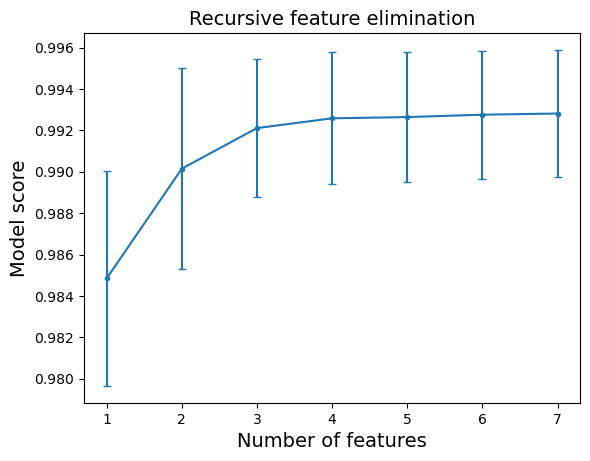

In [57]:
plt.errorbar(x  = rfecv_results["n_features"],y = rfecv_results["mean_test_score"],yerr = rfecv_results["std_test_score"],marker = 'o',markersize = 3, capsize = 3)
plt.xlabel('Number of features', fontsize = 14)
plt.ylabel('Model score', fontsize = 14)
plt.title('Recursive feature elimination', fontsize = 14)

## Hyperparameter tuning

c:\Users\nkdi\AppData\Local\anaconda3\envs\Env_2025_edu\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\nkdi\AppData\Local\anaconda3\envs\Env_2025_edu\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\nkdi\AppData\Local\anaconda3\envs\Env_2025_edu\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1771: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\nkdi\AppData\Local\anaconda3\envs\Env

Best parameters: 
 x1 = 1, 
 x2 = 1, 
 x3 = 0, 
 x4 = 1, 
 x5 = 1, 
 x6 = 1, 
 x7 = 1
Minimum value: -0.9951


<Axes: title={'center': 'Convergence plot'}, xlabel='Number of calls $n$', ylabel='$\\min f(x)$ after $n$ calls'>

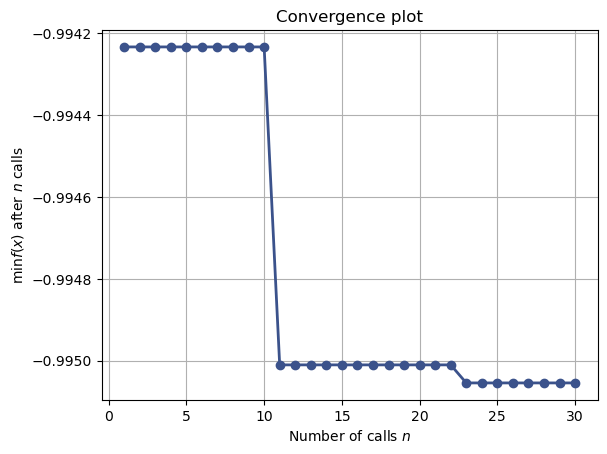

In [58]:
# TRY BAYESIAN OPTIMIZATION FOR FEATURE SELECTION. EACH VARIABLE USE FLAG IS BINARY (ABUSE OF METHOD!)
from skopt import gp_minimize
from skopt.space import Real, Integer
from skopt.plots import plot_convergence

# Define the objective function to minimize
def objective_function(x):
    Xtraini = Xtrain[:, np.asarray(x) == 1]
    Xtesti = Xtest[:, np.asarray(x) == 1]
    ANNmodeli = sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(20,20), activation = 'relu')
    ANNmodeli.fit(Xtraini,Ytrain)
    S = -ANNmodeli.score(Xtesti,Ytest)
    return S

# Define the search space
space = [Integer(0, 1, name = InputFeatures[0]),  
         Integer(0, 1, name = InputFeatures[1]),
         Integer(0, 1, name = InputFeatures[2]),
         Integer(0, 1, name = InputFeatures[3]),
         Integer(0, 1, name = InputFeatures[4]),
         Integer(0, 1, name = InputFeatures[5]),
         Integer(0, 1, name = InputFeatures[6])]  # Binary for x1 - x7

dimensions = [(0,1),(0,1),(0,1),(0,1),(0,1),(0.1),(0,1)]

# Perform Bayesian Optimization
result = gp_minimize(objective_function,      # The function to minimize
                     space,                   # The search space
                     n_calls=30,              # The number of evaluations
                     random_state=10)         # Random state for reproducibility

# Print the best parameters and the corresponding minimum value
print("Best parameters: \n x1 = {:.0f}, \n x2 = {:.0f}, \n x3 = {:.0f}, \n x4 = {:.0f}, \n x5 = {:.0f}, \n x6 = {:.0f}, \n x7 = {:.0f}".format(result.x[0], result.x[1], result.x[2], result.x[3], result.x[4], result.x[5], result.x[6]))
print("Minimum value: {:.4f}".format(result.fun))

# Plot convergence
plot_convergence(result)

In [59]:
# FINAL LIST OF FEATURES
NBMFeatures = [InputFeatures[i] for i in list(np.where(result.x)[0])]

XscalerNBM = sklearn.preprocessing.StandardScaler()
XscalerNBM.fit(TurbineData[NBMFeatures])
YscalerNBM = sklearn.preprocessing.StandardScaler()
YscalerNBM.fit(TurbineData[[TargetFeatures]])

XtrainNBM = XscalerNBM.transform(TurbineData.loc[(TrainingPeriod & NaNindex & NormalProd_index),NBMFeatures])
XtestNBM = XscalerNBM.transform(TurbineData.loc[(TestingPeriod & NaNindex & NormalProd_index),NBMFeatures])

#Ytrain = Yscaler.transform(TurbineData.loc[(TrainingPeriod & NaNindex & NormalProd_index),[TargetFeatures]]) # Extra brackets on Target Features needed because it is a 1-D array
#Ytest = Yscaler.transform(TurbineData.loc[(TestingPeriod & NaNindex & NormalProd_index),[TargetFeatures]])


Best parameters: 
 x1 = 45, 
 x2 = 39
Minimum value: -0.9953


<Axes: title={'center': 'Convergence plot'}, xlabel='Number of calls $n$', ylabel='$\\min f(x)$ after $n$ calls'>

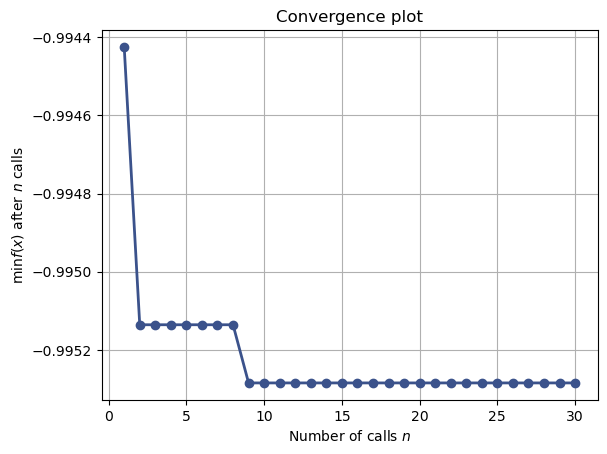

In [60]:
# BAYESIAN OPTIMIZATION FOR HYPERPARAMETER TUNING OF ANN LAYER SIZES
from skopt import gp_minimize
from skopt.space import Real, Integer
from skopt.plots import plot_convergence

# Define the objective function to minimize
def objective_function_par_tuning(x):
    ANNmodeli = sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(x[0],x[1]), activation = 'relu')
    ANNmodeli.fit(XtrainNBM,Ytrain.ravel())
    S = -ANNmodeli.score(XtestNBM,Ytest.ravel())
    return S

# Define the search space
space_par_tuning = [Integer(10, 50, name = 'Layer 1'),  
                    Integer(10, 50, name = 'Layer 2')]

# Perform Bayesian Optimization
result_par_tuning = gp_minimize(objective_function_par_tuning,      # The function to minimize
                     space_par_tuning,                   # The search space
                     n_calls=30,              # The number of evaluations
                     random_state=10)         # Random state for reproducibility

# Print the best parameters and the corresponding minimum value
print("Best parameters: \n x1 = {:.0f}, \n x2 = {:.0f}".format(result_par_tuning.x[0], result_par_tuning.x[1]))
print("Minimum value: {:.4f}".format(result_par_tuning.fun))

# Plot convergence
plot_convergence(result_par_tuning)

In [61]:
NBM_ANN = sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(result_par_tuning.x[0],result_par_tuning.x[1]), activation = 'relu')
NBM_ANN.fit(XtrainNBM,Ytrain.ravel())
NBM_ANN.score(XtestNBM,Ytest.ravel())

0.9951243135210567

# PART 4: MODEL EVALUATION AND ALARM CRITERIA

In [62]:
# EVALUATE THE NBM OVER THE ENTIRE DATASET (FOR "POWER OK" STATUS)

NBMinputvalid = TurbineData[NBMFeatures].isna().sum(axis = 1)==0

NBMpower = Yscaler.inverse_transform(NBM_ANN.predict(XscalerNBM.transform(TurbineData.loc[NBMinputvalid,NBMFeatures])).reshape(-1, 1))
NBMpower[NBMpower < 0] = 0

TurbineData["NBMpower"] = np.nan
TurbineData.loc[NBMinputvalid,"NBMpower"] = NBMpower
NBMresiduals = TurbineData.loc[NBMinputvalid,"NBMpower"] - TurbineData.loc[NBMinputvalid,"Power (kW)"]

TurbineData["NBMresidual"] = 0.0
TurbineData.loc[NBMinputvalid,"NBMresidual"] = NBMresiduals


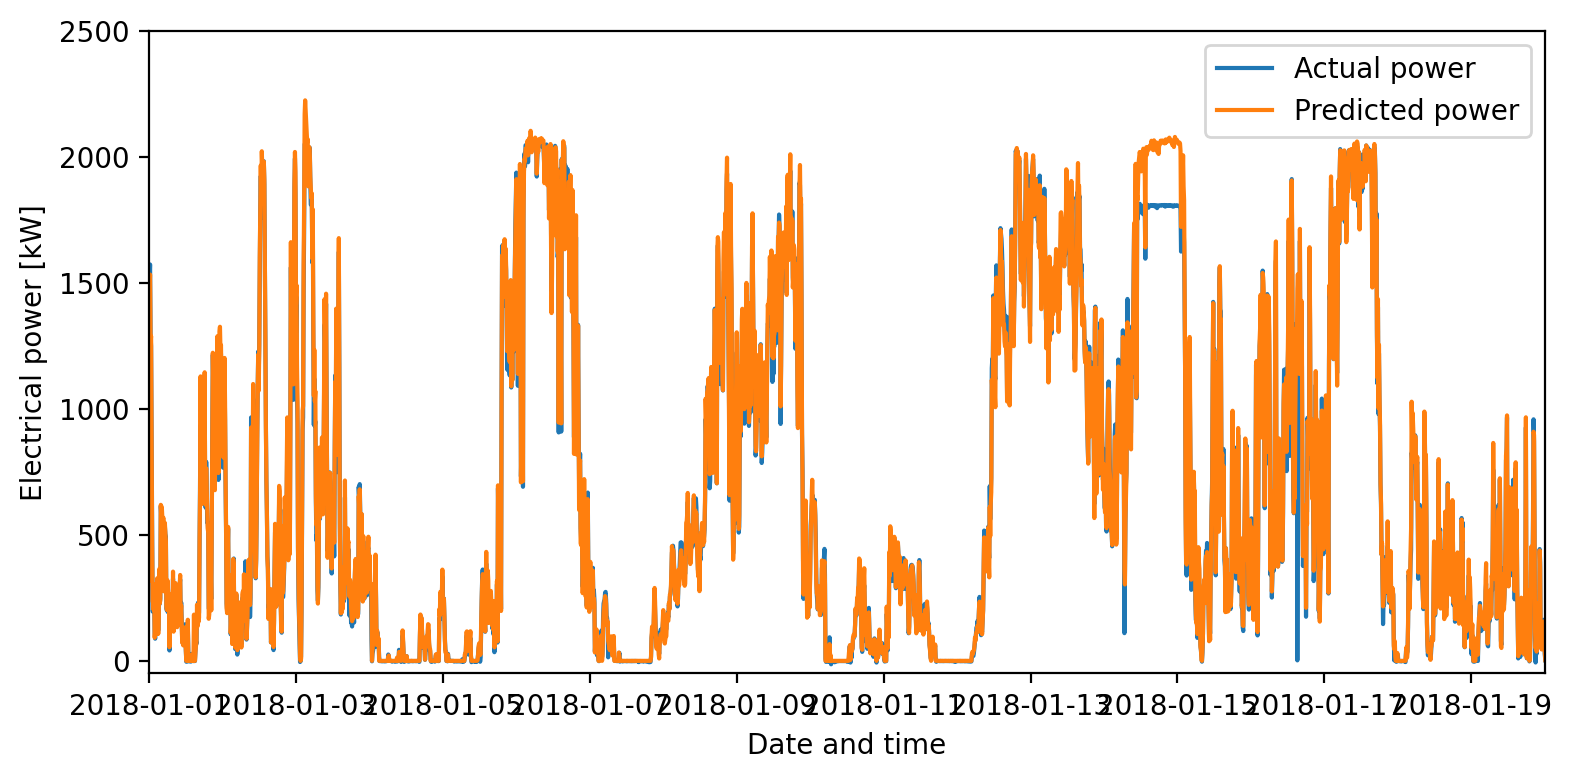

In [63]:
fig4,ax4 = plt.subplots(1,1,figsize = (8,4), dpi = 200)
ax4.plot(TurbineData['# Date and time'],TurbineData['Power (kW)'],label = 'Actual power')
ax4.plot(TurbineData['# Date and time'],TurbineData['NBMpower'], label = 'Predicted power')
ax4.set_xlim(pd.to_datetime(['2018-01-01','2018-01-20']))
ax4.set_ylim([-50,2500])
ax4.set_xlabel('Date and time')
ax4.set_ylabel('Electrical power [kW]')
ax4.legend()
plt.tight_layout()
plt.show()

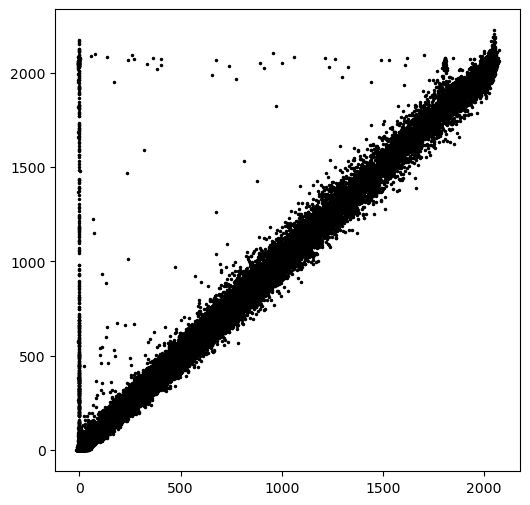

In [64]:
fig5,ax5 = plt.subplots(1,1,figsize = (6,6))
ax5.plot(TurbineData['Power (kW)'],TurbineData['NBMpower'],'.k',markersize = 3)

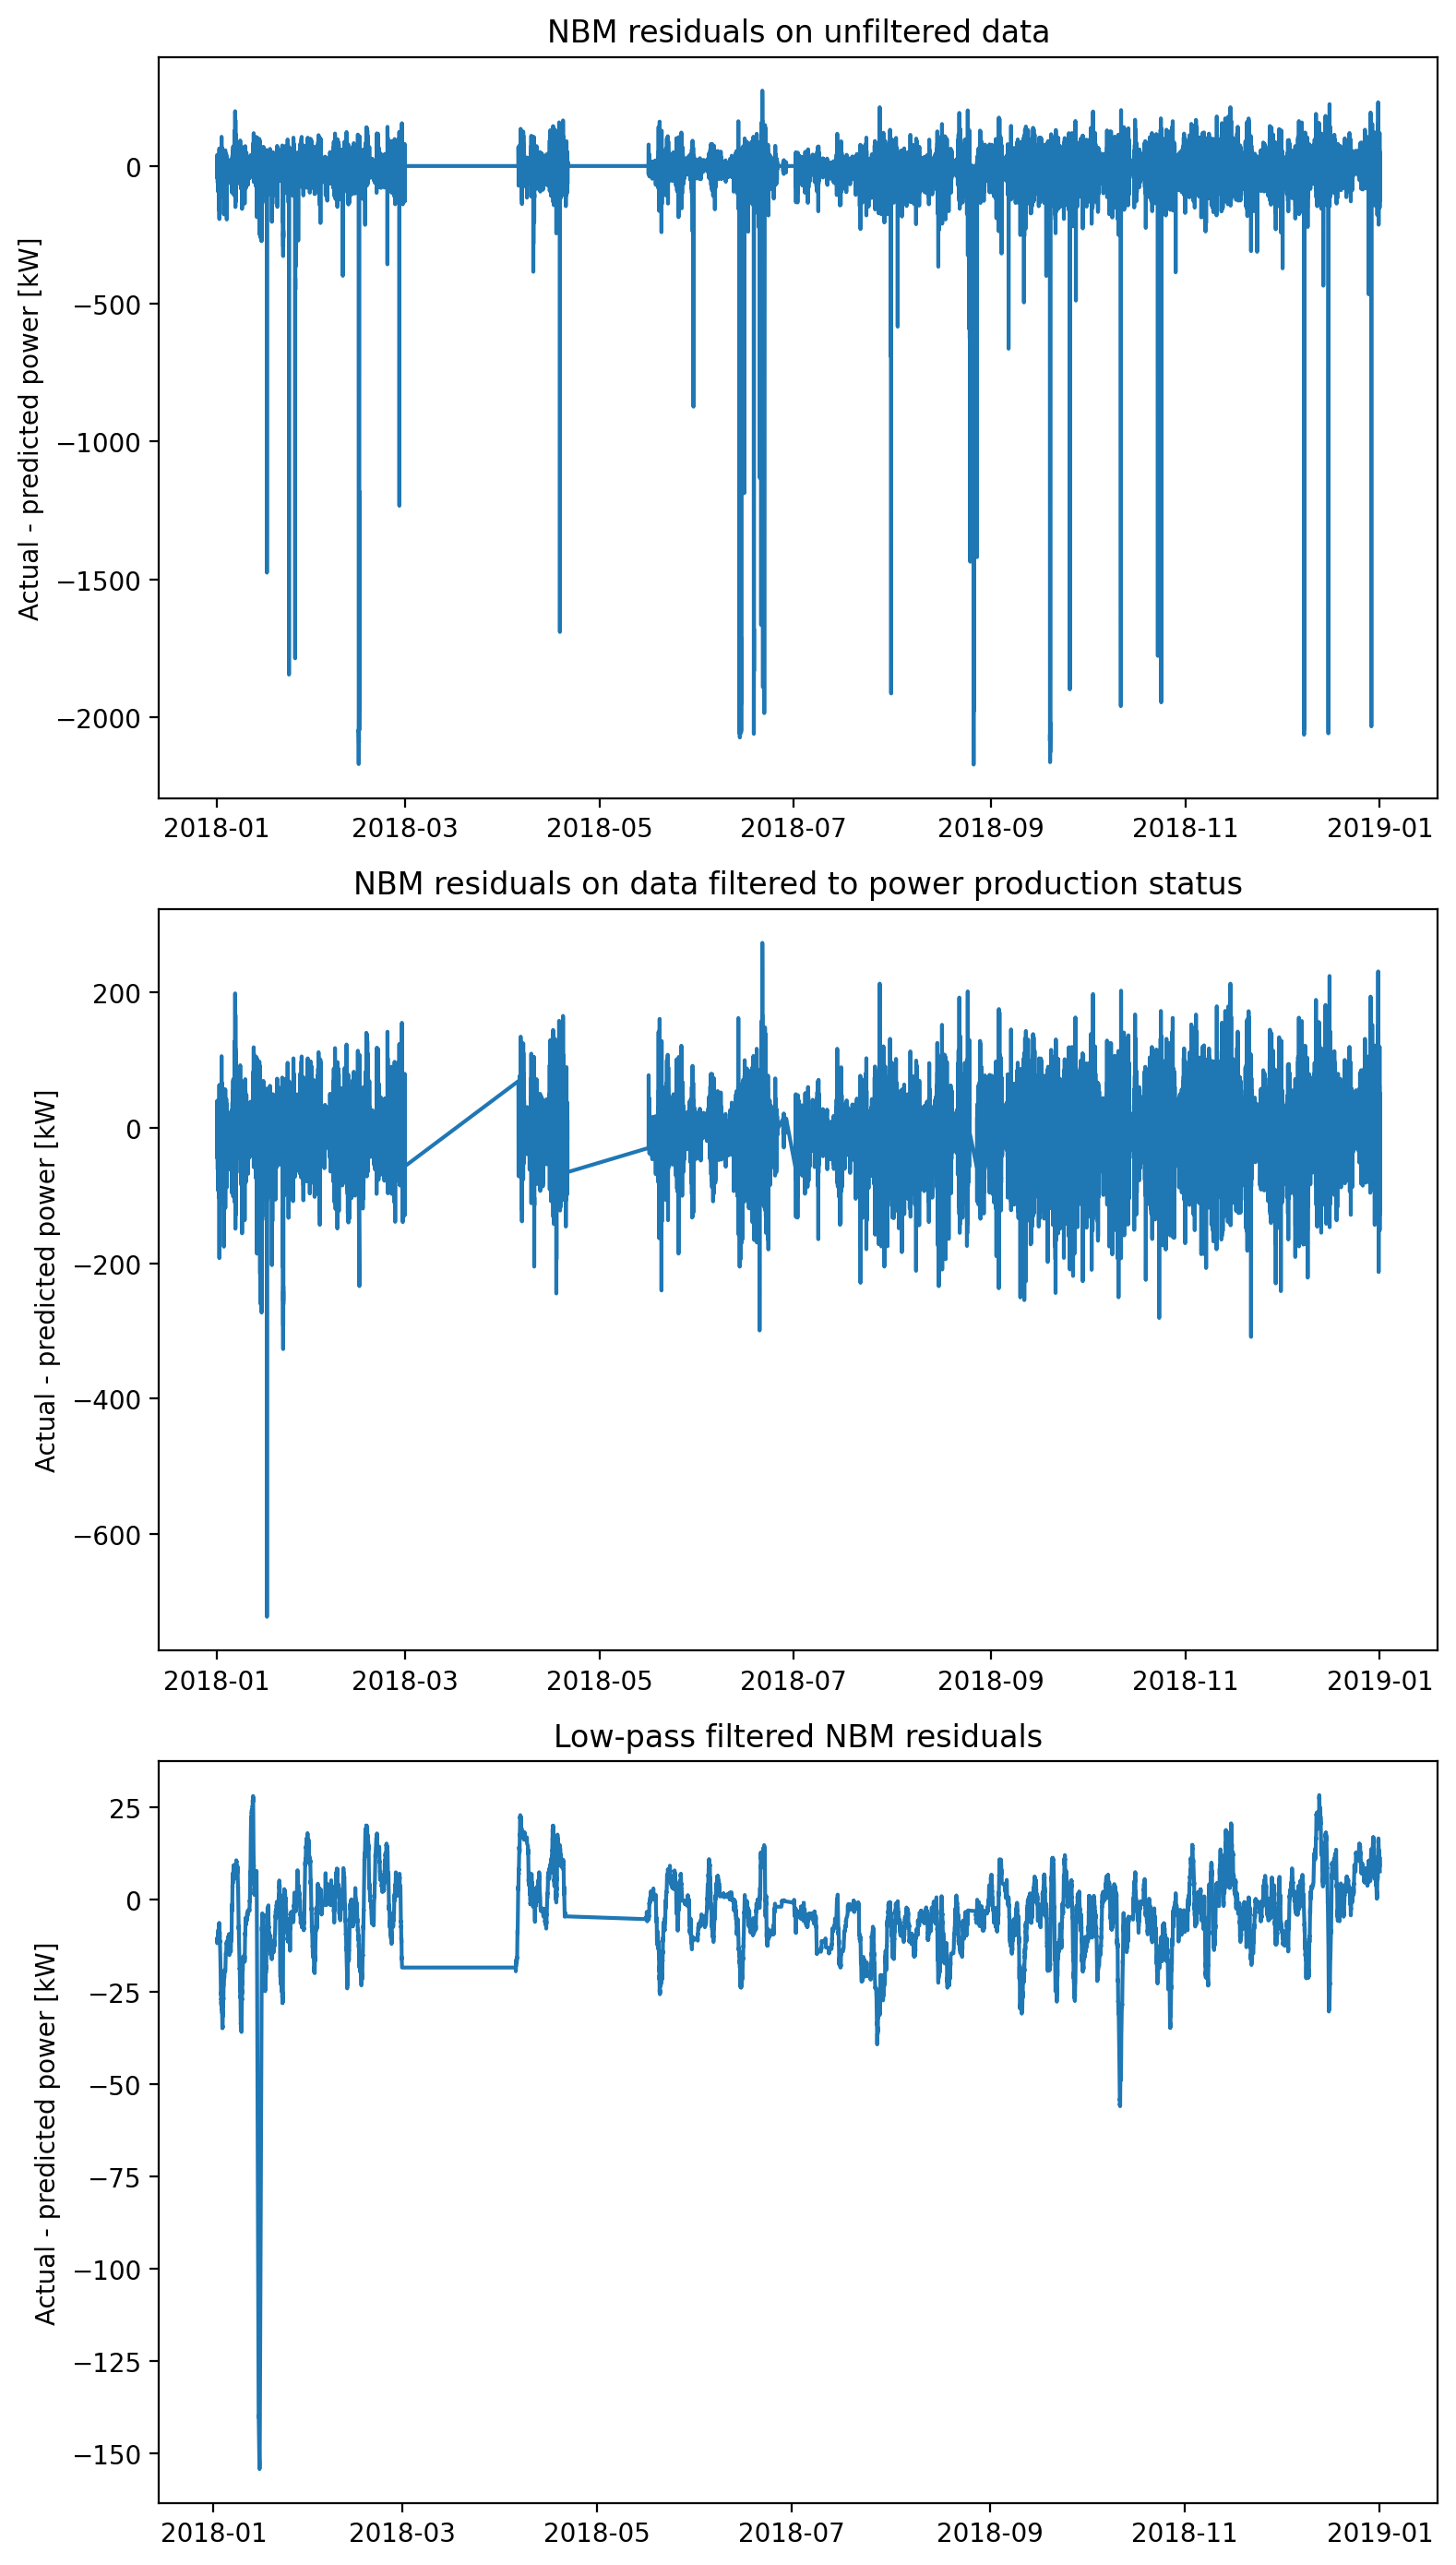

In [65]:
# PLOT RESIDUALS

fig6,ax6 = plt.subplots(3,1,figsize = (8,14),dpi = 200)
ax6[0].plot(TurbineData.loc[:,'# Date and time'],-TurbineData.loc[:,'NBMresidual'], label = 'Residuals')
ax6[0].set_title('NBM residuals on unfiltered data')
ax6[0].set_ylabel('Actual - predicted power [kW]')
ax6[1].plot(TurbineData.loc[(NBMinputvalid & ProductionOK),'# Date and time'],-TurbineData.loc[(NBMinputvalid & ProductionOK),'NBMresidual'], label = 'Residuals, filtered')
ax6[1].set_title('NBM residuals on data filtered to power production status')
ax6[1].set_ylabel('Actual - predicted power [kW]')
ax6[2].plot(TurbineData.loc[(NBMinputvalid & ProductionOK),'# Date and time'],-TurbineData.loc[(NBMinputvalid & ProductionOK),'NBMresidual'].rolling(24*6).mean(), label = '1-day rolling window')
ax6[2].set_title('Low-pass filtered NBM residuals')
ax6[2].set_ylabel('Actual - predicted power [kW]')
plt.tight_layout()


# ADDITIONAL EXAMPLES (CAN BE USEFUL TOO)

In [66]:
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(Xtrain)
print(np.cumsum(pca.explained_variance_ratio_))


[0.69239551 0.91653652 0.9780026  0.99131755 0.99786733 0.99998708
 1.        ]


In [67]:
ANN_PCA = sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(40,40), activation = 'relu',verbose = False)
ANN_PCA.fit(pca.transform(Xtrain)[:,:4],Ytrain.ravel())
ANN_PCA.score(pca.transform(Xtest)[:,:4],Ytest.ravel())

0.9907693251635715

In [68]:
# SEQUENTIAL FEATURE SELECTOR
from sklearn.feature_selection import SequentialFeatureSelector
sfs = SequentialFeatureSelector(sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(20,20),activation = 'relu'), n_features_to_select=4)
sfs.fit(Xtrain, Ytrain.ravel())

,estimator,"MLPRegressor(...izes=(20, 20))"
,n_features_to_select,4
,tol,None
,direction,'forward'
,scoring,None
,cv,5
,n_jobs,None
,loss,'squared_error'
,hidden_layer_sizes,"(20, ...)"
,activation,'relu'
,solver,'adam'


In [69]:
SelectedFeaturesMask = sfs.get_support()
print(SelectedFeaturesMask)

[False  True  True False  True False  True]


In [70]:
SelectedFeatures = []
for i,iFeature in enumerate(InputFeatures): 
    if SelectedFeaturesMask[i] == True:
        SelectedFeatures.append(iFeature)
SelectedFeatures

['Wind speed, Standard deviation (m/s)',
 'Wind speed, Minimum (m/s)',
 'Density adjusted wind speed (m/s)',
 'Wind direction, Standard deviation (°)']

In [71]:
ANN_SFS = sklearn.neural_network.MLPRegressor(hidden_layer_sizes=(40,40), activation = 'relu',verbose = False)
ANN_SFS.fit(Xtrain[:,SelectedFeaturesMask],Ytrain.ravel())
ANN_SFS.score(Xtest[:,SelectedFeaturesMask],Ytest.ravel())

0.99515397943774